## Cell 1 — Mount Google Drive and go to the project

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
ZIP = '/content/drive/MyDrive/CameraTrapML.zip'
PROJECT = '/content/drive/MyDrive/CameraTrapML'
DATA = '/content/data'                        # fast local disk; re-created each session

if not os.path.exists(PROJECT):
    !unzip -q -n "{ZIP}" -d /content/drive/MyDrive/
os.makedirs(DATA, exist_ok=True)
os.chdir(PROJECT)
print('Project folder:', os.getcwd())
print(sorted(os.listdir()))

Mounted at /content/drive
Project folder: /content/drive/MyDrive/CameraTrapML
['.gitignore', 'Dockerfile.constrained', 'README.md', 'examples', 'notebooks', 'requirements.txt', 'scripts', 'src']


## Cell 2 — Install the one missing package and check the GPU

In [ ]:
os.environ['PYTHONWARNINGS'] = 'ignore'   # hides PyTorch deprecation notices, never errors
!pip install -q gradio
!nvidia-smi -L
import torch
print('torch', torch.__version__, '| CUDA available:', torch.cuda.is_available(),
      '| quantized engines:', torch.backends.quantized.supported_engines)

GPU 0: Tesla T4 (UUID: GPU-74836e64-72bc-dc6e-3b36-a318321909d4)
torch 2.14.1+cu130 | CUDA available: True | quantized engines: ['qnnpack', 'onednn', 'x86', 'fbgemm']


## Cell 3 — Smoke test (≈5 min)
Builds a tiny fake dataset and runs every stage.

In [ ]:
!python scripts/smoke_test.py 2>&1 | tail -40
!rm -rf smoke_test_tmp

   int4-qat          96     0.333     0.167       1.282                      9.315                     7.324                   8.615                  0.108
   int8-ptq          96     0.333     0.167       2.345                     10.141                     8.784                   8.553                  0.025
   int8-qat          96     0.333     0.167       2.345                      4.100                     0.229                   8.498                  0.080

$ /content/drive/MyDrive/CameraTrapML/src/plot_results.py --arch mobilenet_v2 --resolution 96
Plotting mobilenet_v2, device tag 'laptop', main resolution 96px
  wrote figures/01_accuracy_vs_bits.png
  wrote figures/02_storage_by_level.png
  wrote figures/03_memory_breakdown.png
  wrote figures/04_latency_vs_batch.png
  wrote figures/05_throughput_vs_batch.png
  wrote figures/06_accuracy_vs_latency.png
  wrote figures/07_accuracy_vs_storage.png
  wrote figures/08_per_class_f1_heatmap.png
  wrote figures/09_confusion_matrices.p

## Cell 4 — Download ENA24 (≈3.6 GB of images + a small metadata file, ≈5 min)

This cell asks Google's public LILA bucket (`gs://public-datasets-lila/ena24/`) which files exist, prints the list,
then downloads the big image zip and the metadata `.json`.

In [ ]:
MANUAL_IMAGES_URL = ''   # leave empty unless the automatic download fails
MANUAL_META_URL   = ''

def fetch(url, dest):
    if url.startswith('gs://'):
        !gsutil -q cp "{url}" "{dest}"
    else:
        !wget -q --show-progress -O "{dest}" "{url}"

if MANUAL_IMAGES_URL:
    img_src, meta_src = MANUAL_IMAGES_URL, MANUAL_META_URL
else:
    listing = !gsutil ls -l gs://public-datasets-lila/ena24/ 2>&1
    print('\n'.join(listing))
    sized = [(int(l.split()[0]), l.split()[-1]) for l in listing
             if 'gs://' in l and l.strip()[:1].isdigit()]
    zips = sorted([x for x in sized if x[1].endswith('.zip')], reverse=True)
    metas = [x for x in sized if x[1].endswith('.json')] or zips[1:]
    assert zips and metas, 'Could not list the bucket — use the MANUAL_* links (see the instructions above).'
    img_src = zips[0][1]                     # the biggest zip = the images
    meta_src = sorted(metas, key=lambda x: ('non' not in x[1], x[0]))[0][1]
print('images   :', img_src)
print('metadata :', meta_src)

fetch(img_src, f'{DATA}/ena24_images.zip')
fetch(meta_src, f'{DATA}/ena24_meta')
size_gb = os.path.getsize(f'{DATA}/ena24_images.zip') / 1e9
print(f'downloaded images zip: {size_gb:.2f} GB')
assert size_gb > 1, 'The images download is too small — use the MANUAL_* links and re-run.'

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
   3775581  2022-10-17T16:54:29Z  gs://public-datasets-lila/ena24/ena24.json
3886355029  2022-10-17T17:03:45Z  gs://public-datasets-lila/ena24/ena24.zip
   3092932  2022-10-17T16:54:34Z  gs://public-datasets-lila/ena24/ena24_public.json
                                 gs://public-datasets-lila/ena24/images/
TOTAL: 3 objects, 3893223542 bytes (3.63 GiB)
images   : gs://public-datasets-lila/ena24/ena24.zip
metadata : gs://public-datasets-lila/ena24/ena24_public.json
downloaded images zip: 3.89 GB


## Cell 5 — Unzip and locate the files (≈3 min)

In [ ]:
# Unzip, then find the image folder and the annotation json wherever they landed.
import glob, zipfile
from pathlib import Path

!unzip -q -n {DATA}/ena24_images.zip -d {DATA}/raw
meta = f'{DATA}/ena24_meta'
if zipfile.is_zipfile(meta):                         # some LILA metadata links are zipped json
    !unzip -q -n {meta} -d {DATA}/raw_meta
    META = glob.glob(f'{DATA}/raw_meta/**/*.json', recursive=True)[0]
else:
    META = meta

jpgs = glob.glob(f'{DATA}/raw/**/*.jpg', recursive=True) + glob.glob(f'{DATA}/raw/**/*.JPG', recursive=True)
IMG_DIR = str(Path(max(set(Path(j).parent for j in jpgs), key=lambda d: sum(1 for j in jpgs if Path(j).parent == d))))
print(len(jpgs), 'images | image folder:', IMG_DIR, '| annotations:', META)

8789 images | image folder: /content/data/raw | annotations: /content/data/ena24_meta


## Cell 6 — Make the animal crops + check the split

In [ ]:
!python src/prepare_ena24.py --images_dir "{IMG_DIR}" --annotations "{META}" --mode crops \
    --crops_out {DATA}/ena24_crops --boxes_out {DATA}/ena24_boxes.json | tail -30
!python src/dataset.py --data_dir {DATA}/ena24_crops

images: 100% 8789/8789 [03:26<00:00, 42.66it/s]
Images with usable boxes: 8789 (missing files: 0)
Crops written to /content/data/ena24_crops: 9772
  American_Black_Bear       959
  American_Crow             1278
  Bird                      225
  Bobcat                    333
  Chicken                   732
  Coyote                    344
  Dog                       726
  Domestic_Cat              482
  Eastern_Chipmunk          311
  Eastern_Cottontail        340
  Eastern_Fox_Squirrel      343
  Eastern_Gray_Squirrel     319
  Grey_Fox                  438
  Horse                     63
  Northern_Raccoon          292
  Red_Fox                   413
  Striped_Skunk             297
  Vehicle                   138
  Virginia_Opossum          725
  White_Tailed_Deer         381
  Wild_Turkey               427
  Woodchuck                 206
Box index: /content/data/ena24_boxes.json
22 classes: ['American_Black_Bear', 'American_Crow', 'Bird', 'Bobcat', 'Chicken', 'Coyote', 'Dog', 'Domesti

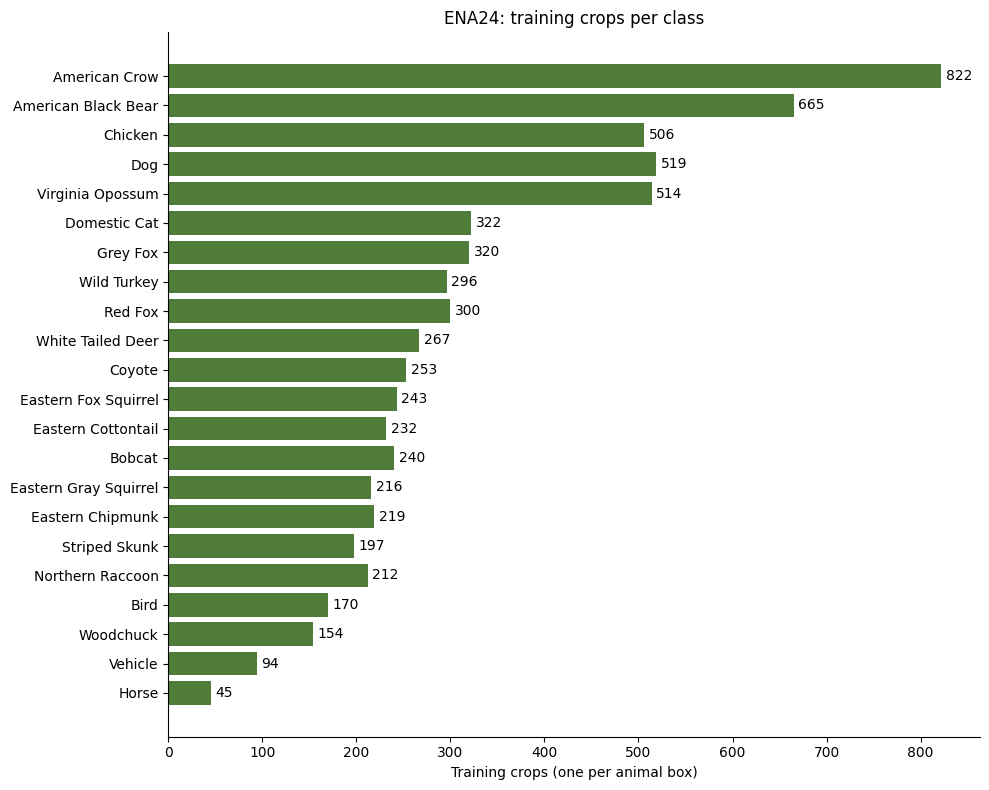

TOTAL crops: 9,772  (train 6,806 | val 1,491 | test 1,475)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys, os
sys.path.insert(0, 'src')
import pandas as pd
import matplotlib.pyplot as plt
from dataset import load_ena24, class_counts

classes, train_ds, val_ds, test_ds = load_ena24(f'{DATA}/ena24_crops', 224)
df = pd.DataFrame({
    'species': [c.replace('_', ' ') for c in classes],
    'train': class_counts(train_ds),
    'val': class_counts(val_ds),
    'test': class_counts(test_ds),
})
df['total'] = df[['train', 'val', 'test']].sum(axis=1)
df = df.sort_values('total', ascending=True)

os.makedirs('figures', exist_ok=True)
df.sort_values('total', ascending=False).to_csv('figures/00_class_counts.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(df['species'], df['train'], color='#4f7d39')
for b, v in zip(bars, df['train']):
    ax.text(b.get_width() + 5, b.get_y() + b.get_height() / 2, str(v), va='center', fontsize=10)
ax.set_xlabel('Training crops (one per animal box)')
ax.set_title('ENA24: training crops per class')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figures/00_class_counts.png', dpi=200)
plt.show()

print(f"TOTAL crops: {df['total'].sum():,}  (train {df['train'].sum():,} | val {df['val'].sum():,} | test {df['test'].sum():,})")

from google.colab import files
files.download('figures/00_class_counts.png')

## Cell 7 — Train the fp32 baseline (≈10 min)
Saves `models/mobilenet_v2_fp32_res224.pt` and its `_meta.json` (with **test** accuracy) to Drive.

In [ ]:
!python src/train_baseline.py --arch mobilenet_v2 --data_dir {DATA}/ena24_crops --resolution 224 \
    --epochs 8 --batch_size 64 --workers 2 --device cuda

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth
100% 13.6M/13.6M [00:00<00:00, 144MB/s]
Fine-tuning mobilenet_v2 @ 224px on 22 classes | train 6806 / val 1491 / test 1475 | device cuda
Epoch 1/8 | loss 2.1976 | val_acc 0.7411 | val_f1 0.7031 | 84s
  -> saved best checkpoint models/mobilenet_v2_fp32_res224.pt
Epoch 2/8 | loss 0.9310 | val_acc 0.7988 | val_f1 0.7597 | 78s
  -> saved best checkpoint models/mobilenet_v2_fp32_res224.pt
Epoch 3/8 | loss 0.6700 | val_acc 0.8612 | val_f1 0.8226 | 74s
  -> saved best checkpoint models/mobilenet_v2_fp32_res224.pt
Epoch 4/8 | loss 0.5692 | val_acc 0.8820 | val_f1 0.8487 | 77s
  -> saved best checkpoint models/mobilenet_v2_fp32_res224.pt
Epoch 5/8 | loss 0.5145 | val_acc 0.8913 | val_f1 0.8629 | 75s
  -> saved best checkpoint models/mobilenet_v2_fp32_res224.pt
Epoch 6/8 | loss 0.4809 | val_acc 0.8954 | val_f1 0.8650 | 76s
  -> saved best checkpoint models/

## Cell 8 — Post-training quantization, every level (≈5 min)
This is the "round a finished model" baseline. Expect int4 and below to collapse.

In [ ]:
!python src/qat_train.py --arch mobilenet_v2 --resolution 224 --fp32_checkpoint models/mobilenet_v2_fp32_res224.pt \
    --method ptq --workers 2 --device cuda


=== mobilenet_v2_int8_ptq_res224 (backend x86) ===
  INTEGER MODEL test acc 0.7905 | test F1 0.7520
  packed file reloads to an identical model: True
  packed n-bit file 2.37 MB (avg 8.00 bits/weight) | 53 layers at int8 (max 255 distinct integer values), 53 kept 8-bit

=== mobilenet_v2_int4_ptq_res224 (backend x86) ===
  INTEGER MODEL test acc 0.6495 | test F1 0.5976
  packed file reloads to an identical model: True
  packed n-bit file 1.31 MB (avg 4.17 bits/weight) | 34 layers at int4 (max 16 distinct integer values), 19 kept 8-bit

=== mobilenet_v2_int3_ptq_res224 (backend x86) ===
  INTEGER MODEL test acc 0.1329 | test F1 0.0541
  packed file reloads to an identical model: True
  packed n-bit file 1.04 MB (avg 3.21 bits/weight) | 34 layers at int3 (max 8 distinct integer values), 19 kept 8-bit

=== mobilenet_v2_int2_ptq_res224 (backend x86) ===
  INTEGER MODEL test acc 0.0197 | test F1 0.0018
  packed file reloads to an identical model: True
  packed n-bit file 0.78 MB (avg 2.25 b

## Cell 9 — Quantization-aware training, every level
**FAST** (3 epochs per level, ≈25 min) fits your two hours. **FULL** uses the per-level defaults
(≈32 epochs total, 1–2 h)

In [ ]:
MODE = 'FULL'          # 'FAST' or 'FULL'
QAT_EXTRA = '--epochs 3' if MODE == 'FAST' else ''

!python src/qat_train.py --arch mobilenet_v2 --resolution 224 --fp32_checkpoint models/mobilenet_v2_fp32_res224.pt \
    --method qat --batch_size 64 --workers 2 --device cuda {QAT_EXTRA}


=== mobilenet_v2_int8_qat_res224 (backend x86) ===
  epoch 1: loss 0.4428 | val_acc 0.8746 | val_f1 0.8323 | 81s
  epoch 2: loss 0.3279 | val_acc 0.8860 | val_f1 0.8485 | 85s
  INTEGER MODEL test acc 0.8732 | test F1 0.8332
  packed file reloads to an identical model: True
  packed n-bit file 2.37 MB (avg 8.00 bits/weight) | 53 layers at int8 (max 255 distinct integer values), 53 kept 8-bit

=== mobilenet_v2_int4_qat_res224 (backend x86) ===
  initialised from the previous level's QAT weights (progressive)
  epoch 1: loss 0.4566 | val_acc 0.8638 | val_f1 0.8305 | 100s
  epoch 2: loss 0.3017 | val_acc 0.8920 | val_f1 0.8693 | 98s
  epoch 3: loss 0.2667 | val_acc 0.8887 | val_f1 0.8492 | 92s
  epoch 4: loss 0.2378 | val_acc 0.8887 | val_f1 0.8532 | 95s
  INTEGER MODEL test acc 0.8847 | test F1 0.8625
  packed file reloads to an identical model: True
  packed n-bit file 1.31 MB (avg 4.17 bits/weight) | 34 layers at int4 (max 16 distinct integer values), 19 kept 8-bit

=== mobilenet_v2_in

New cell after Cell 9: the input-size study (~40 min, GPU)

Slide 9 already promises 128 and 160 px for fp32, int8, int4 and 1.58-bit, and this makes that true. It also produces 11_resolution_effect.png. Add a cell below Cell 9:

In [ ]:
for R in [128, 160]:
    !python src/train_baseline.py --arch mobilenet_v2 --data_dir {DATA}/ena24_crops --resolution {R} \
        --epochs 8 --batch_size 64 --workers 2 --device cuda
    !python src/qat_train.py --arch mobilenet_v2 --resolution {R} --fp32_checkpoint models/mobilenet_v2_fp32_res{R}.pt \
        --method qat --levels int8 int4 1.58bit --batch_size 64 --workers 2 --device cuda --epochs 4

Fine-tuning mobilenet_v2 @ 128px on 22 classes | train 6806 / val 1491 / test 1475 | device cuda
Epoch 1/8 | loss 2.1993 | val_acc 0.7297 | val_f1 0.6895 | 51s
  -> saved best checkpoint models/mobilenet_v2_fp32_res128.pt
Epoch 2/8 | loss 0.9287 | val_acc 0.7700 | val_f1 0.7239 | 50s
  -> saved best checkpoint models/mobilenet_v2_fp32_res128.pt
Epoch 3/8 | loss 0.6688 | val_acc 0.8478 | val_f1 0.8022 | 50s
  -> saved best checkpoint models/mobilenet_v2_fp32_res128.pt
Epoch 4/8 | loss 0.5821 | val_acc 0.8618 | val_f1 0.8246 | 49s
  -> saved best checkpoint models/mobilenet_v2_fp32_res128.pt
Epoch 5/8 | loss 0.5266 | val_acc 0.8799 | val_f1 0.8510 | 50s
  -> saved best checkpoint models/mobilenet_v2_fp32_res128.pt
Epoch 6/8 | loss 0.4865 | val_acc 0.8853 | val_f1 0.8533 | 50s
  -> saved best checkpoint models/mobilenet_v2_fp32_res128.pt
Epoch 7/8 | loss 0.4695 | val_acc 0.8947 | val_f1 0.8686 | 49s
  -> saved best checkpoint models/mobilenet_v2_fp32_res128.pt
Epoch 8/8 | loss 0.4632 | va

## Cell 10 — Copy one held-out test photo per species into `examples/` (for the app, the demo and slides)
These are full frames whose crops were **never used for training**, so the demo is honest.

In [ ]:
import sys, json, random, shutil
sys.path.insert(0, 'src')
from dataset import load_ena24

classes, _, _, test_ds = load_ena24(f'{DATA}/ena24_crops', 224)
stem_to_file = {Path(r['file']).stem: r['file'] for r in json.load(open(f'{DATA}/ena24_boxes.json'))}
by_class = {}
for i in test_ds.indices:
    path, y = test_ds.dataset.samples[i]
    by_class.setdefault(classes[y], []).append(path)

os.makedirs('examples', exist_ok=True)
random.seed(0)
copied = 0
for cls, paths in sorted(by_class.items()):
    random.shuffle(paths)
    for p in paths:
        parts = Path(p).stem.split('_')                  # crop name = <image stem>_<annotation id>
        stem = next(('_'.join(parts[:k]) for k in range(len(parts) - 1, 0, -1)
                     if '_'.join(parts[:k]) in stem_to_file), None)
        if stem:
            shutil.copy(stem_to_file[stem], f'examples/{cls}_{stem}.jpg')
            copied += 1
            break
print(copied, 'example photos in examples/:', sorted(os.listdir('examples'))[:6], '...')

22 example photos in examples/: ['American_Black_Bear_9114.jpg', 'American_Crow_7808.jpg', 'Bird_67.jpg', 'Bobcat_7454.jpg', 'Chicken_6249.jpg', 'Coyote_7355.jpg'] ...


## Cell 11 — Benchmark sweep (on Colab's CPU)
Timing runs on the **CPU** (that's what a camera trap has). Each config is its own fresh process.
Three short runs:

* **a.** fp32 + QAT models at batch 1/4/16, 2 repeats → speed, memory, accuracy (≈12 min)
* **b.** PTQ models at batch 1 only, merged into the same results (≈4 min) → the PTQ line on Figure 3
* **c.** the "constrained hardware" proxy: **1 CPU thread** (≈3 min) → Figure 7

Label everything as **Colab CPU** in the slides (or re-run this on your laptop later with `--tag laptop`).

In [ ]:
!python src/run_sweep.py --arch mobilenet_v2 --levels fp32 int8 int4 int3 int2 1.58bit 1bit --methods qat \
    --batch_sizes 1 4 8 16 --repeats 3 --max_trials 30 --tag colab_cpu 2>&1 | tail -40

[W1117 21:15:54.051295206 Quantizer.cpp:111] Warning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (function operator())
  bs=16 rep=3 |   13.16 ms/img |    76.0 img/s | batch p95   238.7 ms | load    4.7 MB | peak   36.6 MB | trials 5

1bit-qat @ 224px: test acc 0.7166 (±0.0119) F1 0.6283
[W1117 21:16:48.519601442 Quantizer.cpp:111] Warning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (function operator())
  bs= 1 rep=1 |   21.59 ms/img |  

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### Cell 12

In [ ]:
!python src/run_sweep.py --arch mobilenet_v2 --levels int8 int4 int3 int2 1.58bit 1bit --methods ptq \
    --batch_sizes 1 --repeats 1 --max_trials 8 --tag colab_cpu --append


int8-ptq @ 224px: test acc 0.7905 (±0.0105) F1 0.7520
[W1117 21:30:11.173462841 Quantizer.cpp:111] Warning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (function operator())
  bs= 1 rep=1 |   21.26 ms/img |    54.6 img/s | batch p95    41.7 ms | load    4.5 MB | peak    9.9 MB | trials 8

int4-ptq @ 224px: test acc 0.6495 (±0.0121) F1 0.5976
[W1117 21:31:14.731460401 Quantizer.cpp:111] Warning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (

Then add one cell after Cell 12 that benchmarks the 128/160 px models into the same results, so the resolution figure gets drawn:

In [ ]:
!python src/run_sweep.py --arch mobilenet_v2 --levels fp32 int8 int4 1.58bit --methods qat \
    --batch_sizes 1 --resolutions 128 160 --repeats 3 --tag colab_cpu --append


fp32 @ 128px: test acc 0.8895 (±0.0081) F1 0.8584
  bs= 1 rep=1 |   21.71 ms/img |    54.8 img/s | batch p95    39.9 ms | load    9.8 MB | peak   27.3 MB | trials 30
  bs= 1 rep=2 |   21.79 ms/img |    54.0 img/s | batch p95    40.6 ms | load    9.8 MB | peak   24.2 MB | trials 30
  bs= 1 rep=3 |   21.80 ms/img |    53.5 img/s | batch p95    41.4 ms | load    9.8 MB | peak   27.3 MB | trials 30

int8-qat @ 128px: test acc 0.8739 (±0.0085) F1 0.8424
[W1117 21:40:56.719298943 Quantizer.cpp:111] Warning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (function operator())
  bs= 1 rep=1 |    6.25 ms/img |   160.2 img/s | batch p95     8.4 ms | load    4.6 MB | peak    8.8 MB | trials 5
[W1117 21:41:06.476692710 Quantiz

### Cell 13

In [ ]:
!python src/run_sweep.py --arch mobilenet_v2 --levels fp32 int8 int4 int3 int2 1.58bit 1bit --methods qat \
    --batch_sizes 1 4 --repeats 3 --max_trials 20 --threads 1 --skip_accuracy --tag colab_1thread


fp32 @ 224px: test acc 0.9017 (±0.0080) F1 0.8855
  bs= 1 rep=1 |   31.27 ms/img |    32.4 img/s | batch p95    42.3 ms | load    9.8 MB | peak   33.9 MB | trials 20
  bs= 1 rep=2 |   31.50 ms/img |    32.2 img/s | batch p95    42.2 ms | load    9.8 MB | peak   31.6 MB | trials 20
  bs= 1 rep=3 |   31.95 ms/img |    31.7 img/s | batch p95    43.3 ms | load    9.8 MB | peak   33.9 MB | trials 20
  bs= 4 rep=1 |   30.40 ms/img |    33.3 img/s | batch p95   157.8 ms | load    9.7 MB | peak   69.9 MB | trials 20
  bs= 4 rep=2 |   30.58 ms/img |    33.1 img/s | batch p95   162.1 ms | load    9.7 MB | peak   72.2 MB | trials 20
  bs= 4 rep=3 |   30.21 ms/img |    33.5 img/s | batch p95   156.6 ms | load    9.7 MB | peak   79.8 MB | trials 20

int8-qat @ 224px: test acc 0.8732 (±0.0087) F1 0.8332
[W1117 22:02:29.507438328 Quantizer.cpp:111] Warning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8

### Cell 14

Optional (≈3 min): fp16. It's very slow on CPUs, which is itself a finding for the Discussion slide.

In [ ]:
!python src/run_sweep.py --arch mobilenet_v2 --levels fp16 --batch_sizes 1 --repeats 1 --max_trials 5 \
    --tag colab_cpu --append


fp16 @ 224px: test acc 0.9017 (±0.0080) F1 0.8854
  bs= 1 rep=1 |  941.54 ms/img |     1.1 img/s | batch p95  2819.1 ms | load    5.5 MB | peak   13.8 MB | trials 5

Done in 22.0 min
Raw:     results/mobilenet_v2_colab_cpu_raw.csv
Summary: results/mobilenet_v2_colab_cpu_summary.csv
    variant  resolution  accuracy  f1_macro  storage_mb  latency_ms_per_image_mean  latency_ms_per_image_std  peak_inference_mb_mean  peak_inference_mb_std
1.58bit-ptq         224     0.033     0.004       0.669                     15.695                       NaN                   9.875                    NaN
1.58bit-qat         128     0.628     0.525       0.669                      7.471                     1.142                   8.773                  0.127
1.58bit-qat         160     0.692     0.610       0.669                      9.783                     1.723                   9.207                  0.031
1.58bit-qat         224     0.784     0.732       0.669                     21.598          

## Cell 15 — Make the figures and download them

In [ ]:
!python src/plot_results.py --arch mobilenet_v2 --results_dir results --out_dir figures --tag colab_cpu
!zip -qr /content/figures_and_results.zip figures results/*.csv models/*.json
from google.colab import files
files.download('/content/figures_and_results.zip')

Plotting mobilenet_v2, device tag 'colab_cpu', main resolution 224px
  wrote figures/01_accuracy_vs_bits.png
  wrote figures/02_storage_by_level.png
  wrote figures/03_memory_breakdown.png
  wrote figures/04_latency_vs_batch.png
  wrote figures/05_throughput_vs_batch.png
  wrote figures/06_accuracy_vs_latency.png
  wrote figures/07_accuracy_vs_storage.png
  wrote figures/08_per_class_f1_heatmap.png
  wrote figures/09_confusion_matrices.png
  wrote figures/10_memory_vs_batch.png
  wrote figures/11_resolution_effect.png
  wrote figures/12_device_comparison.png

| model | accuracy | macro F1 | size (MB) | ms/img (bs 1) | img/s (bs 16) | peak RAM MB |
|---|---|---|---|---|---|---|
| fp32 | 0.902 ± 0.008 | 0.885 | 9.26 | 50.8 ± 3.5 | 22.9 ± 0.2 | 38.7 ± 2.7 |
| fp16 | 0.902 ± 0.008 | 0.885 | 4.67 (2.0× smaller) | 941.5 | — | 13.8 |
| int8-qat | 0.873 ± 0.009 | 0.833 | 2.37 (3.9× smaller) | 17.7 ± 3.3 | 76.6 ± 0.4 | 10.2 ± 0.1 |
| int8-ptq | 0.791 ± 0.010 | 0.752 | 2.37 (3.9× smaller) | 21.3

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Cell 16

**00_class_counts.png**

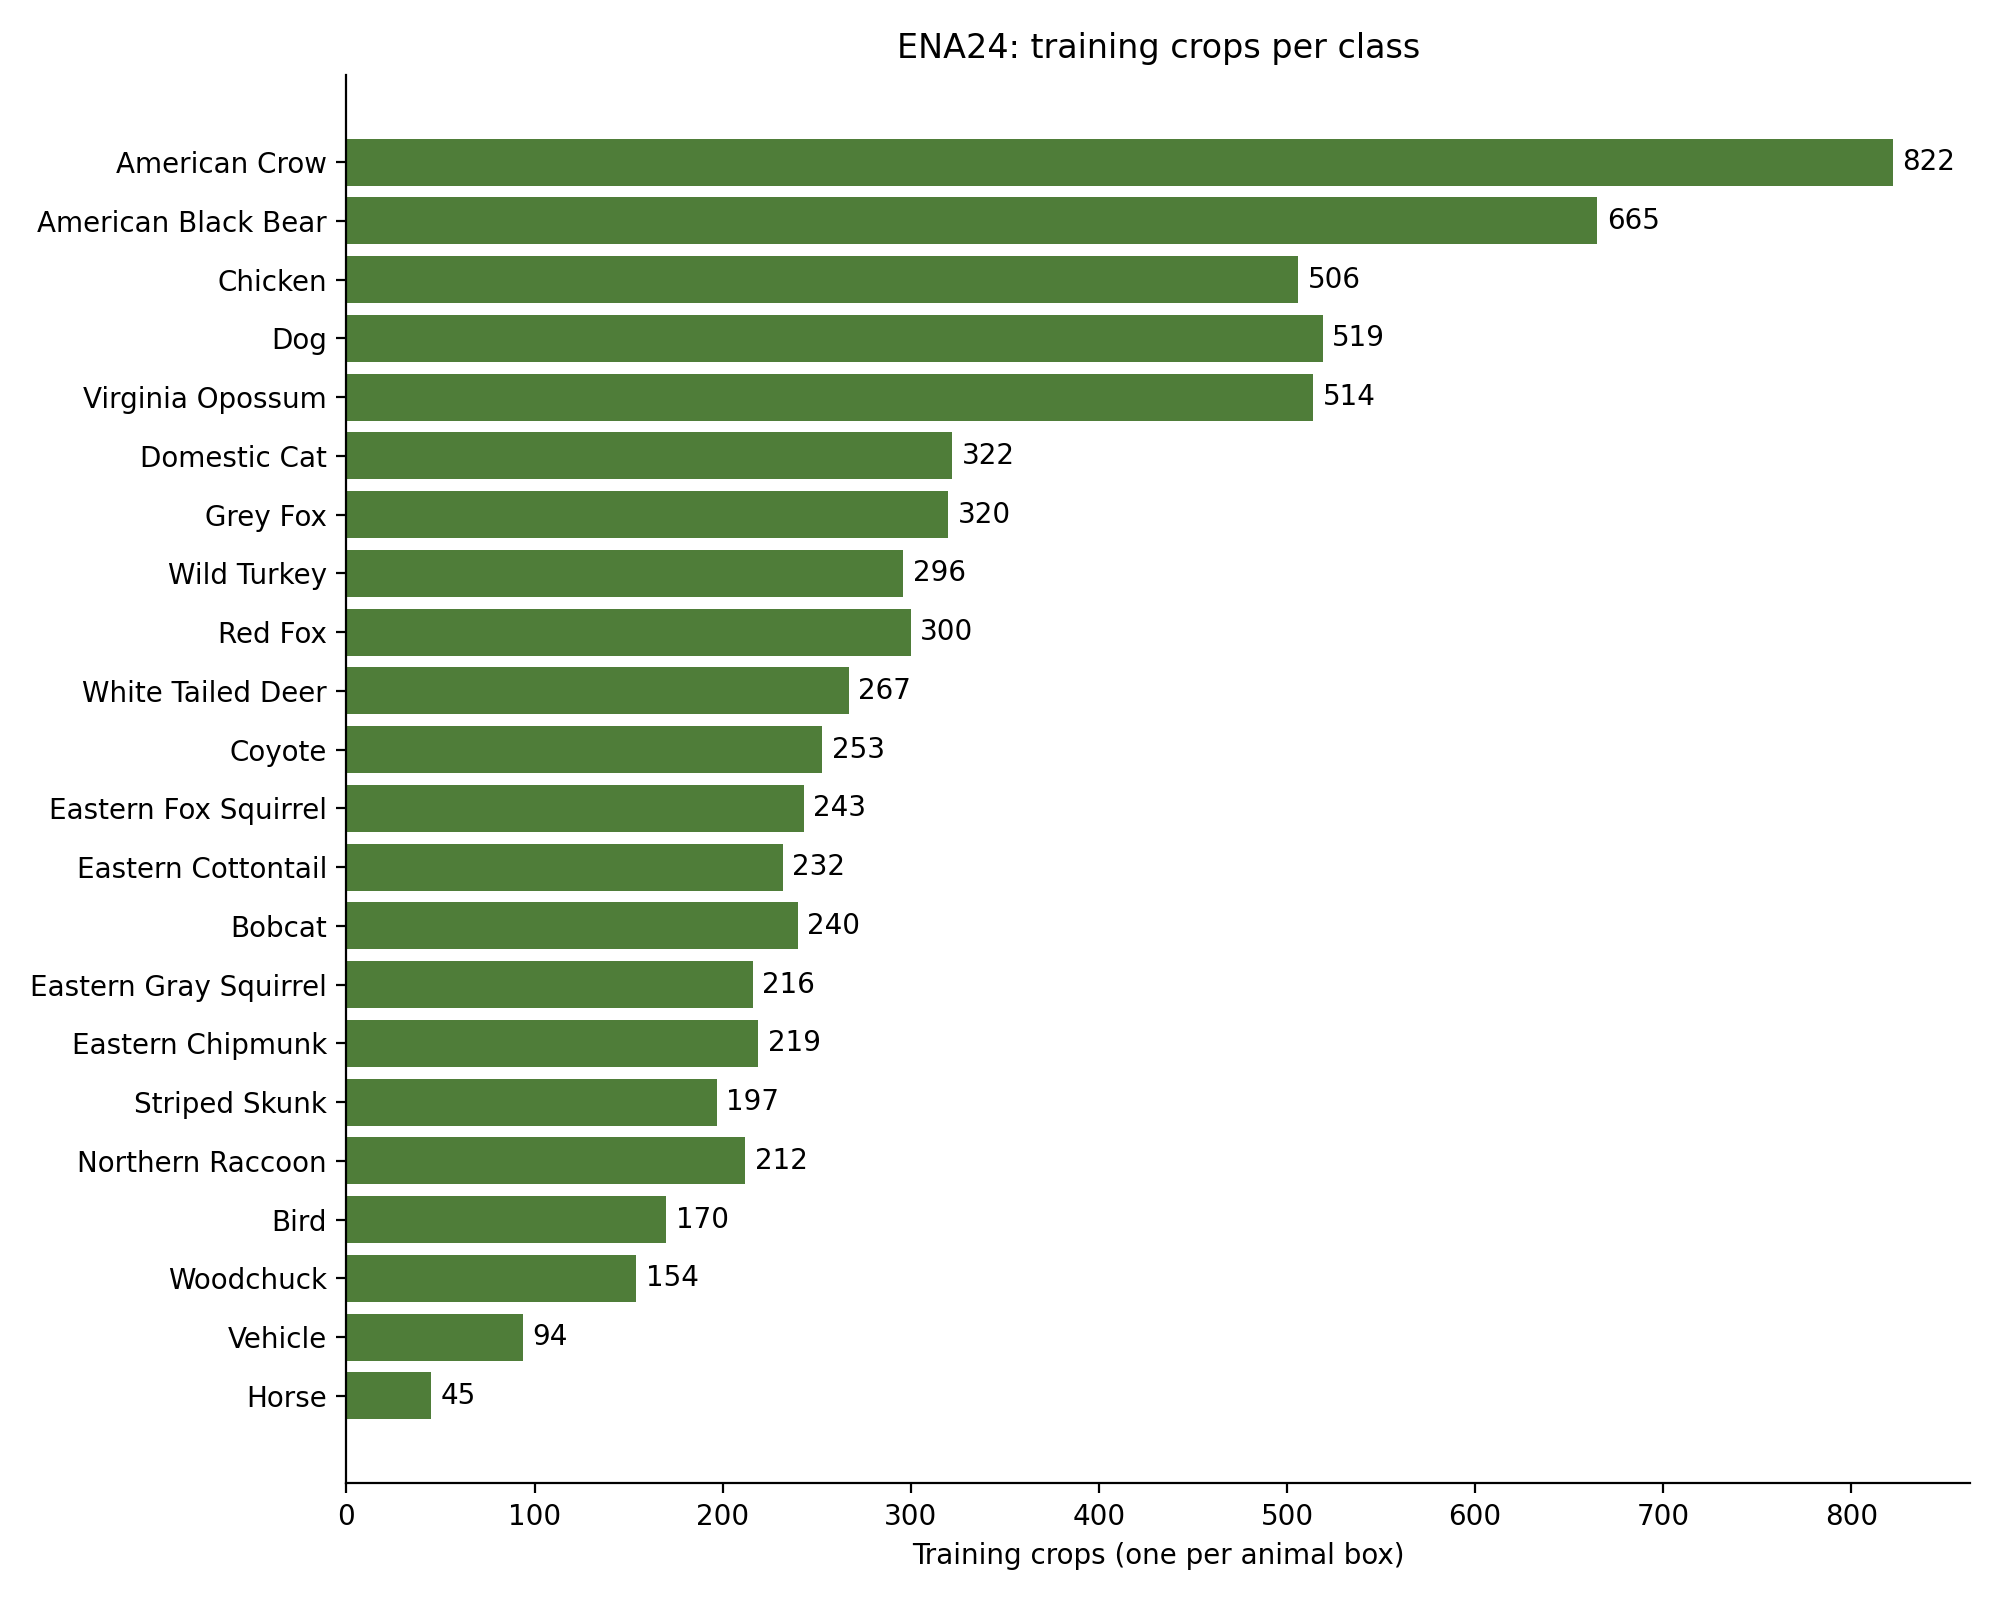

**01_accuracy_vs_bits.png**

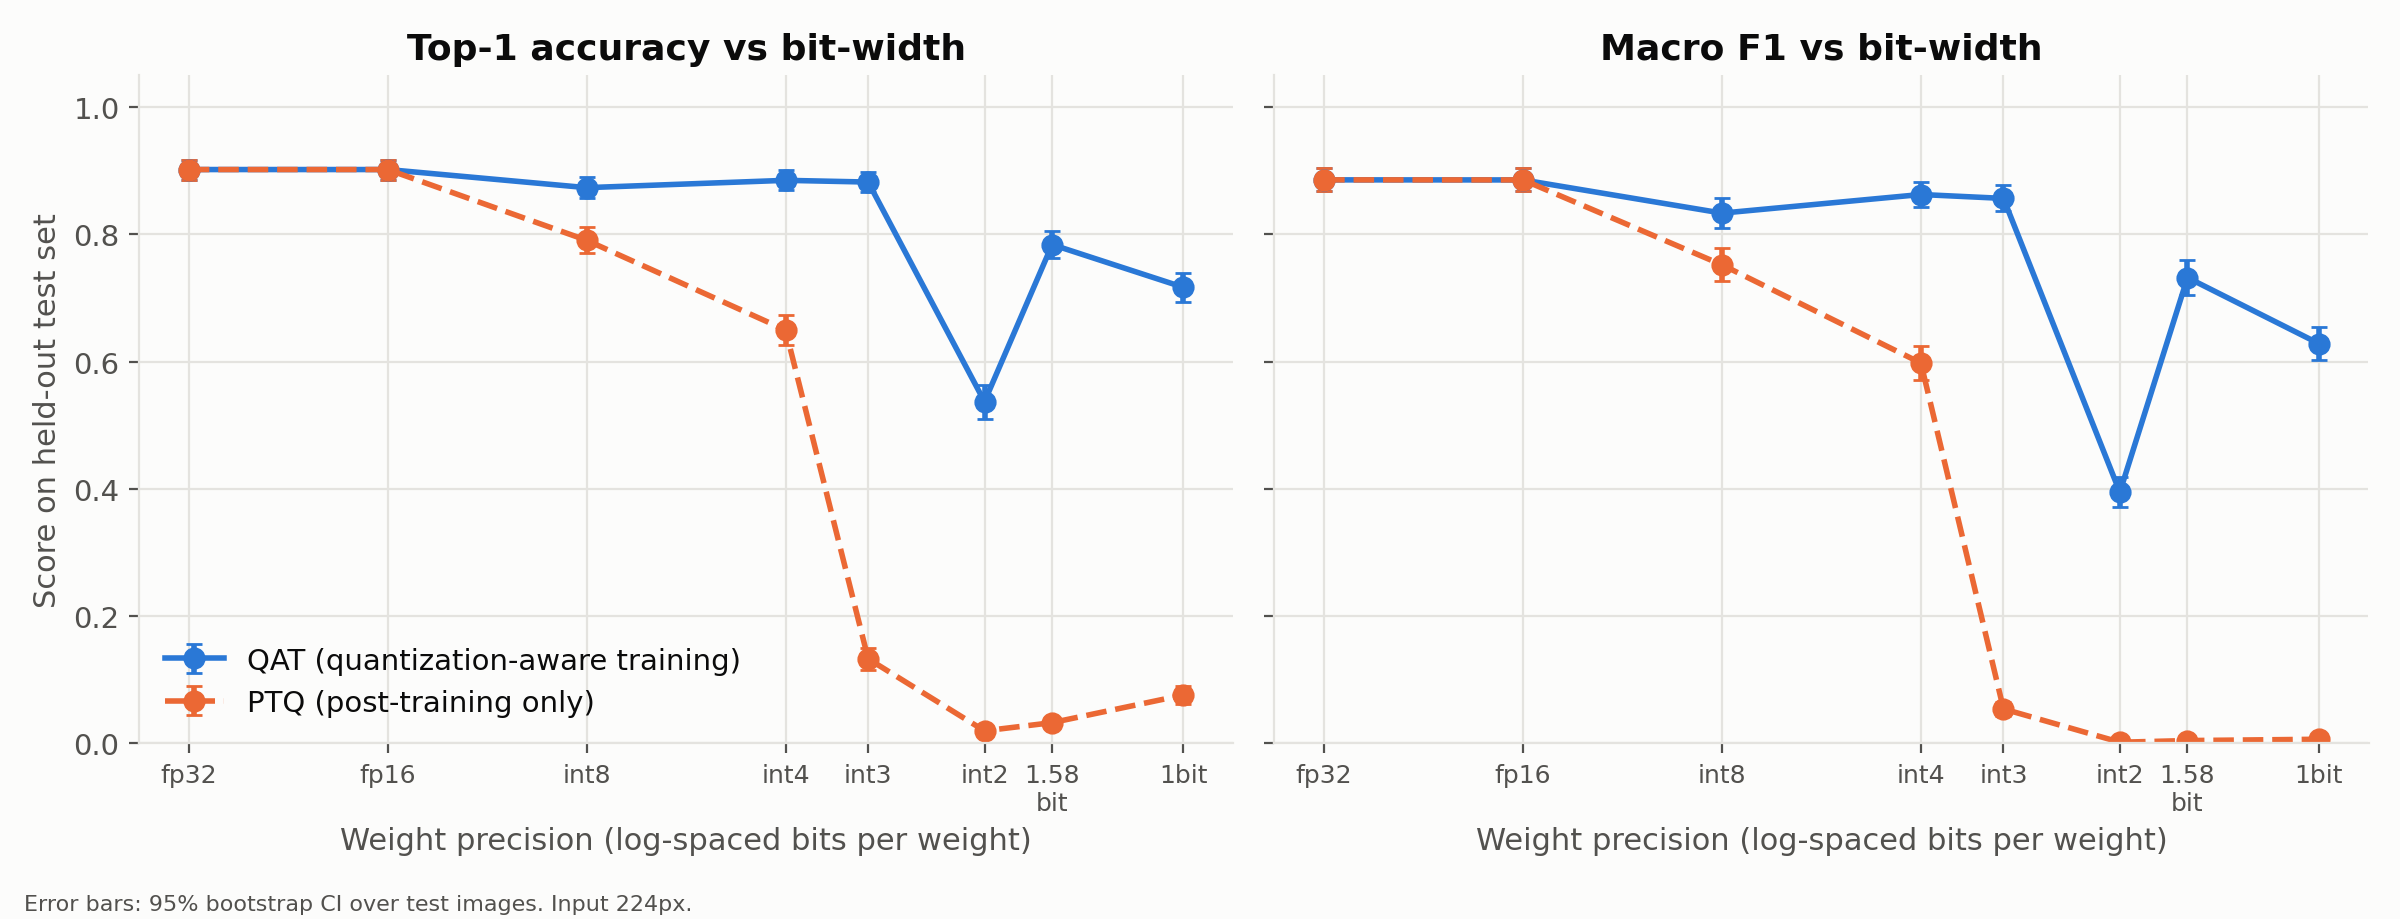

**02_storage_by_level.png**

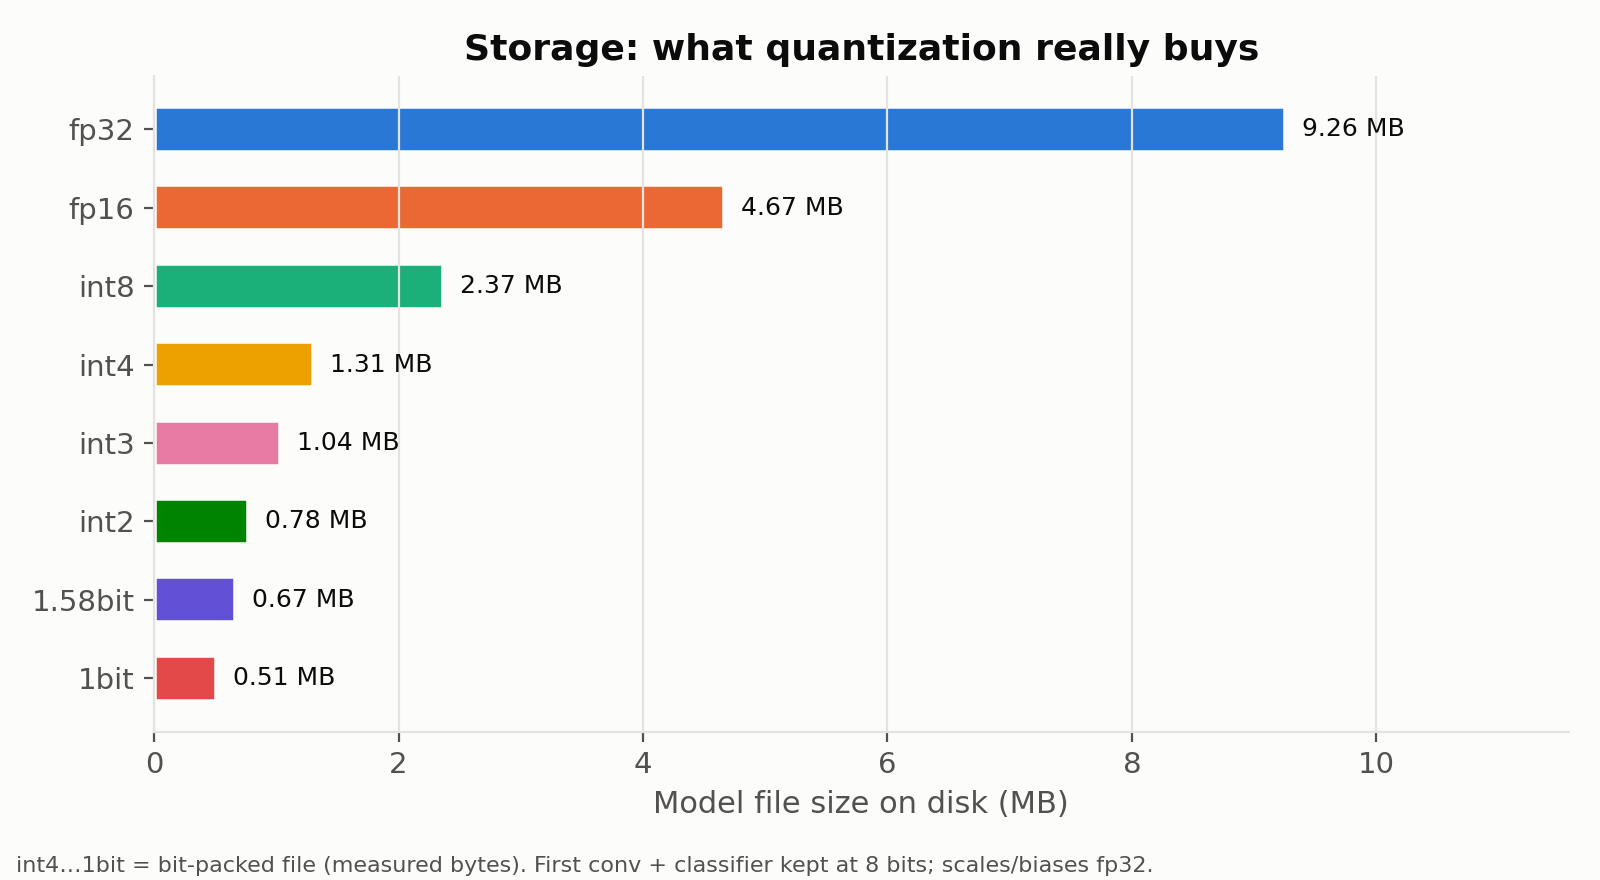

**03_memory_breakdown.png**

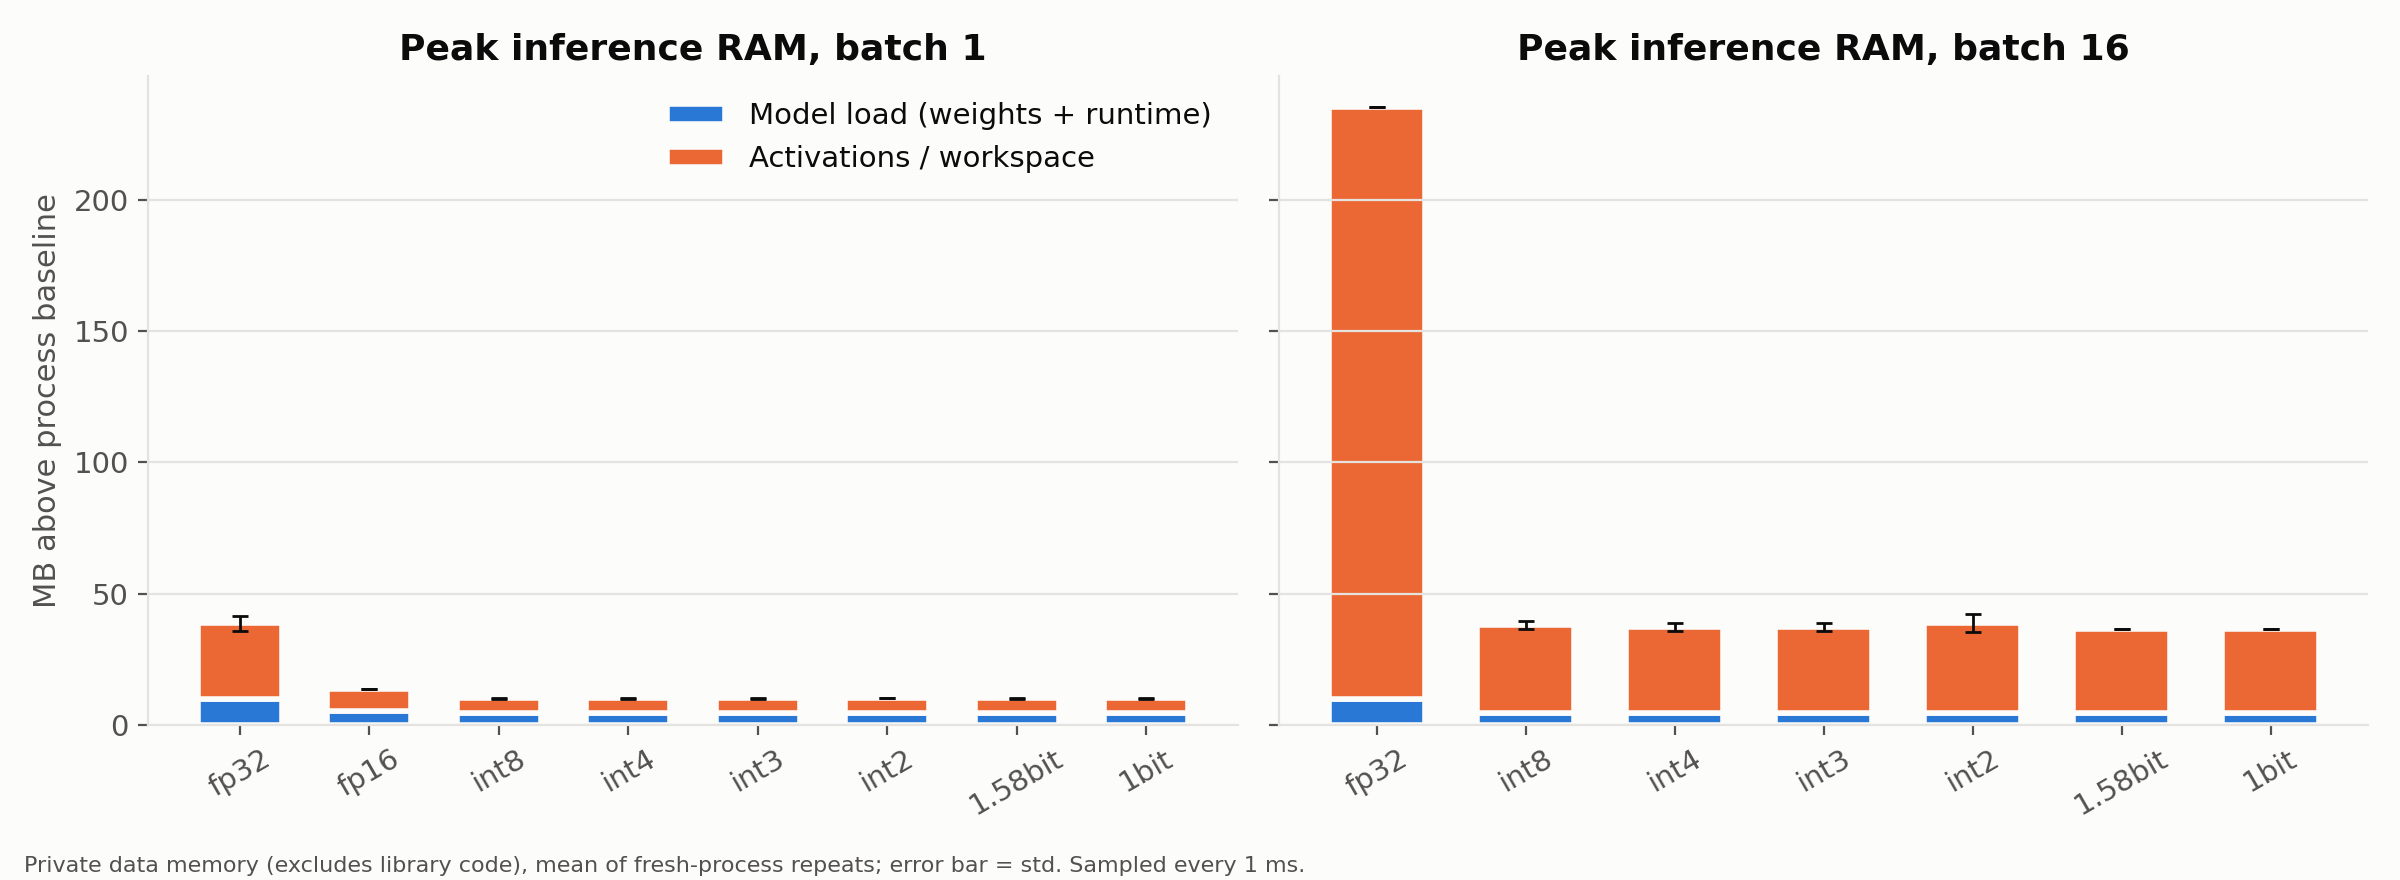

**04_latency_vs_batch.png**

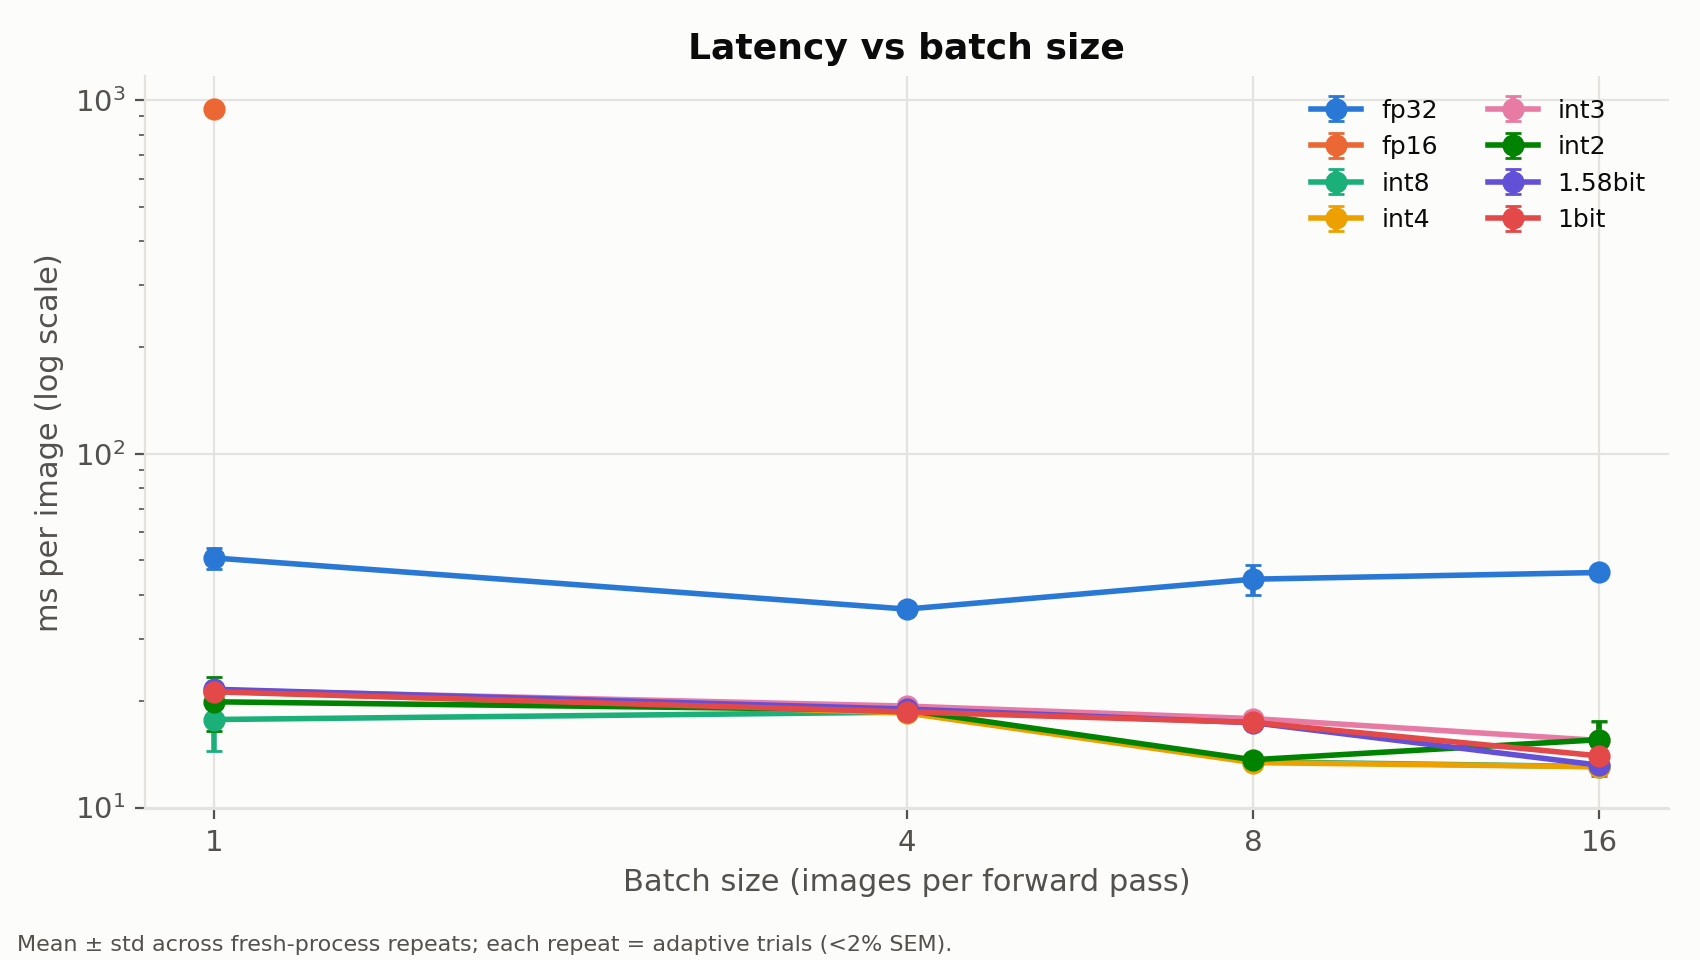

**05_throughput_vs_batch.png**

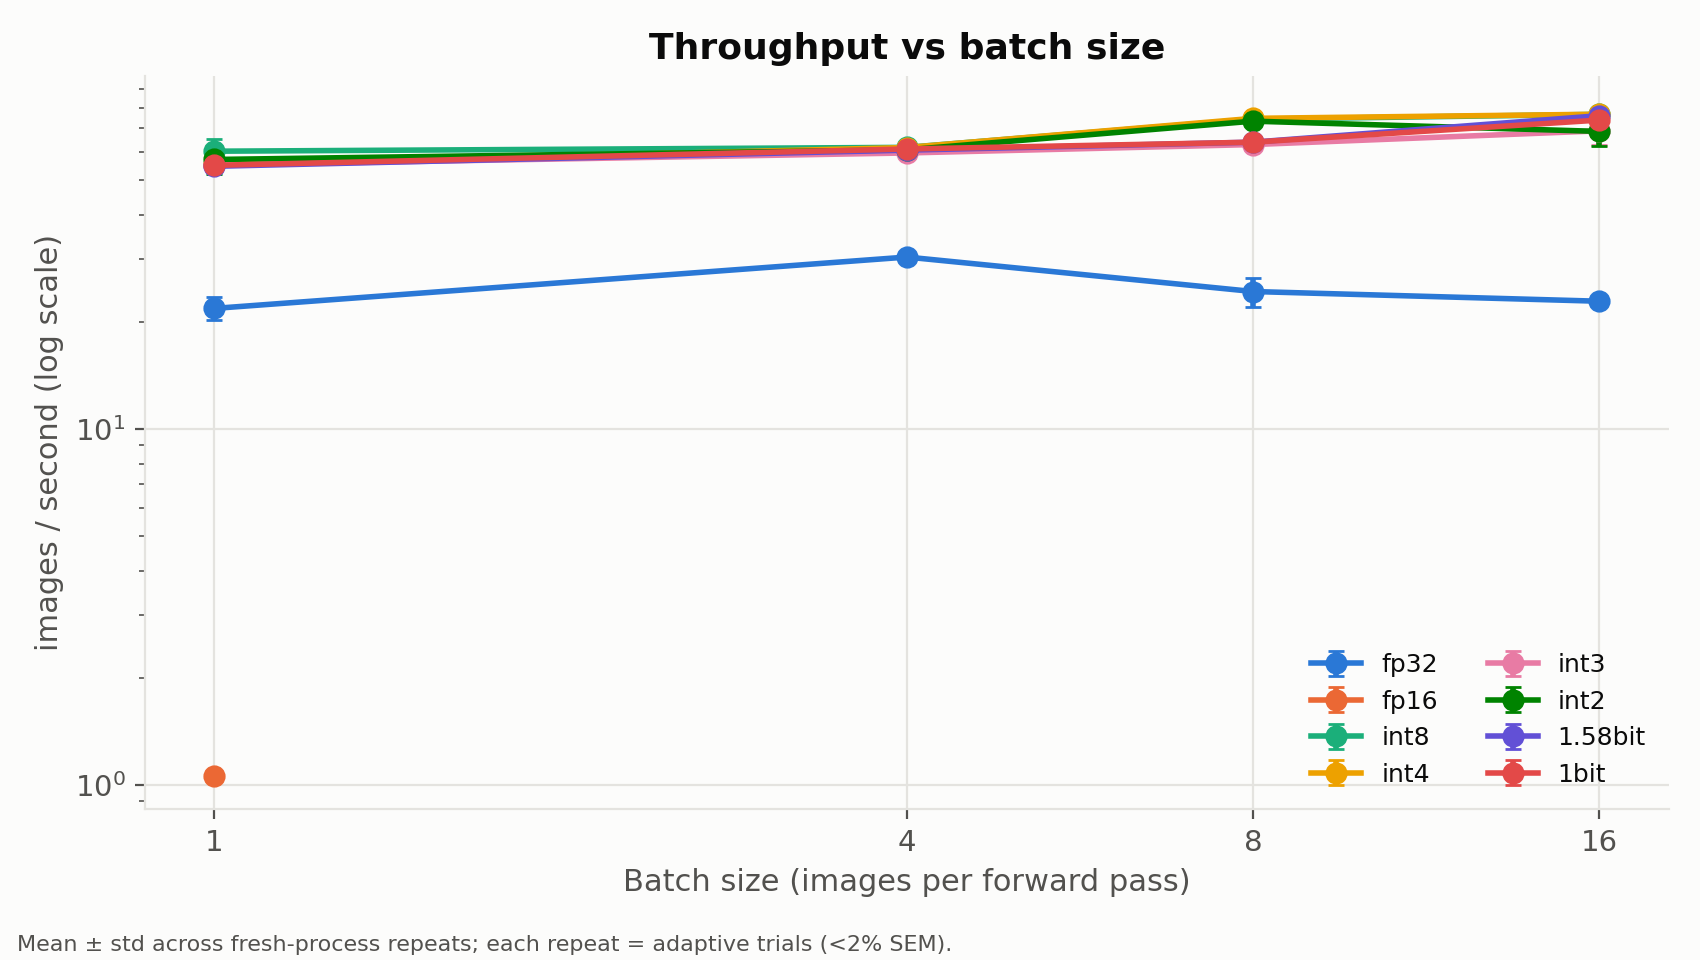

**06_accuracy_vs_latency.png**

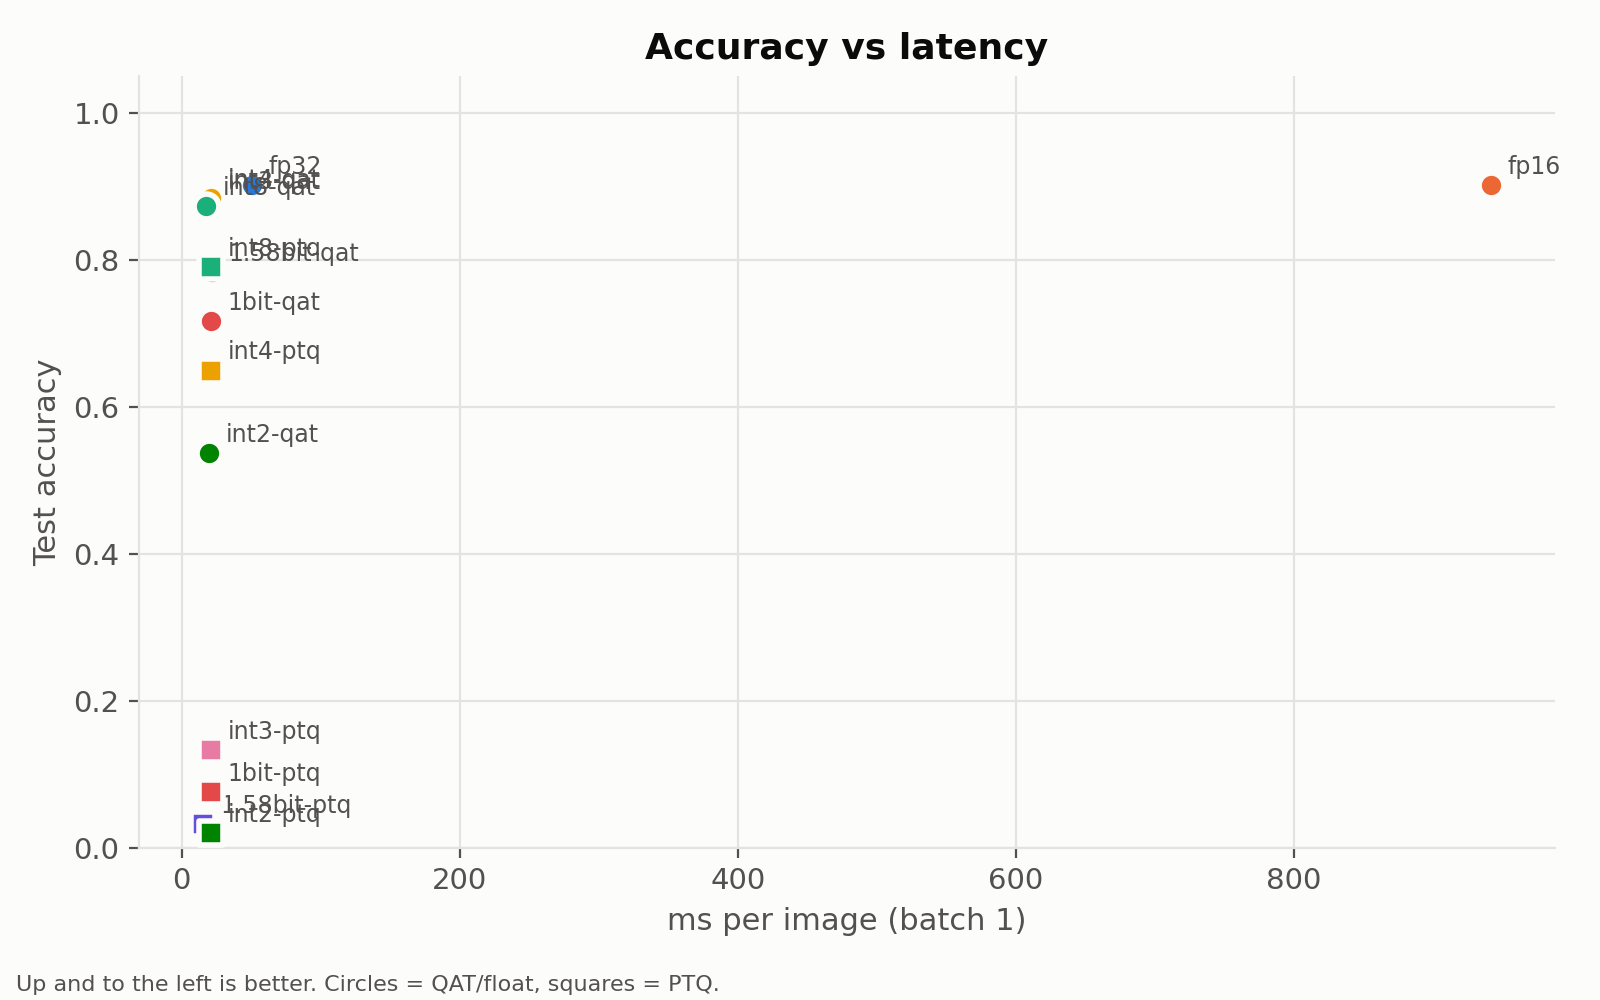

**07_accuracy_vs_storage.png**

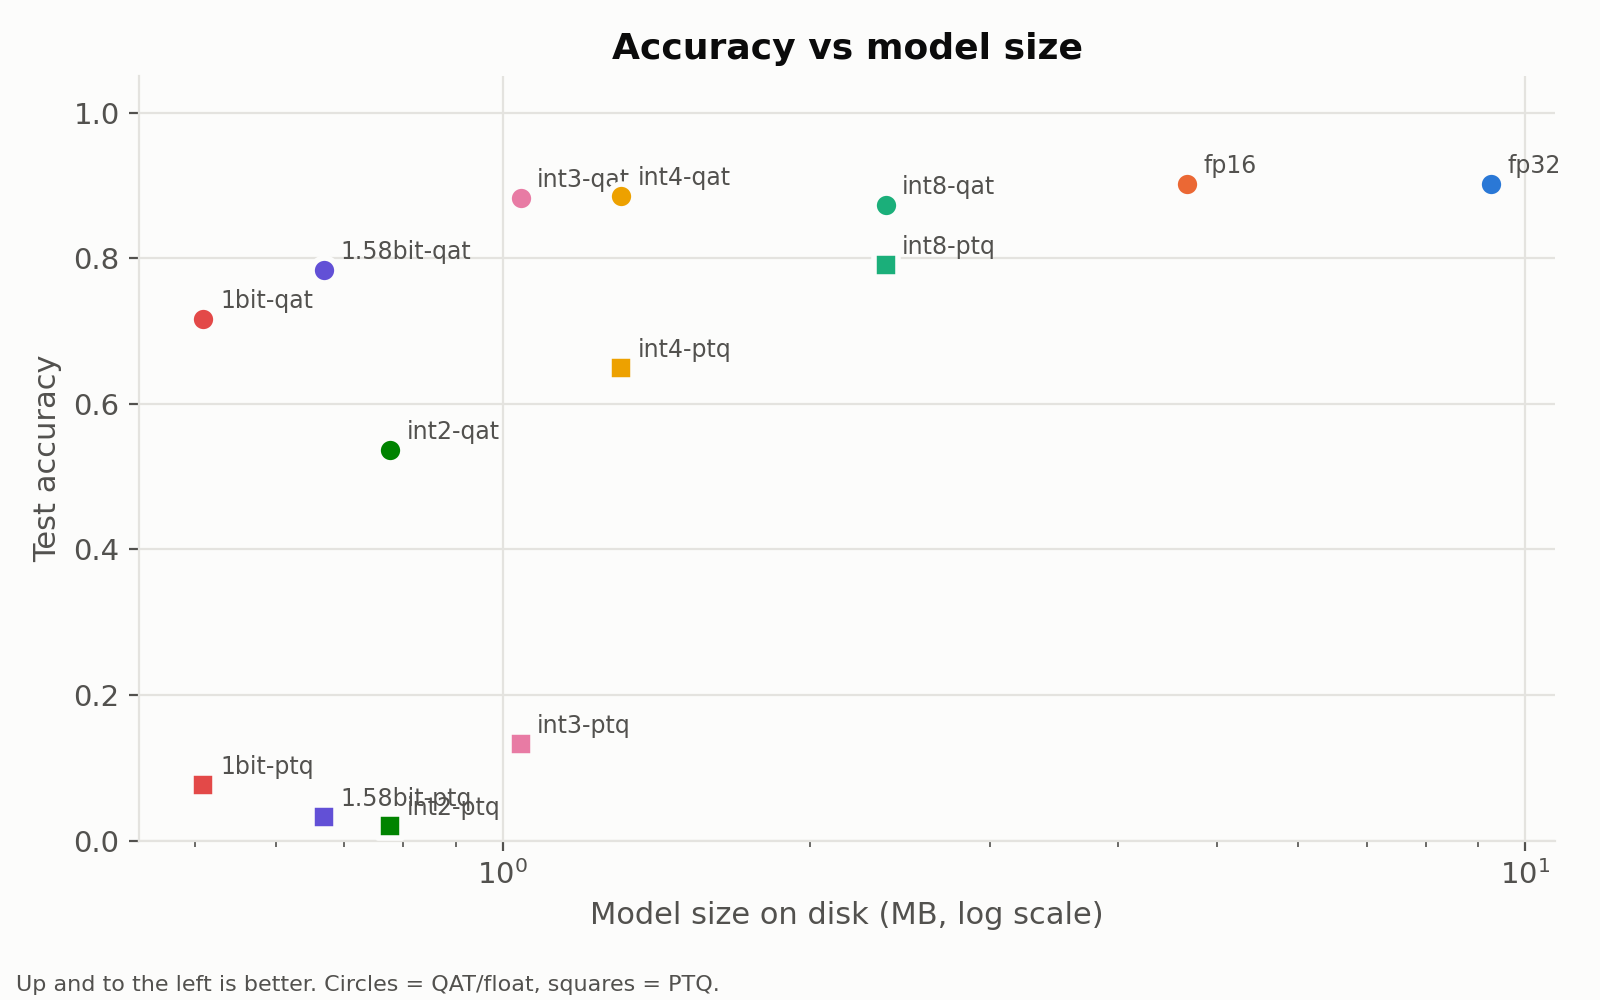

**08_per_class_f1_heatmap.png**

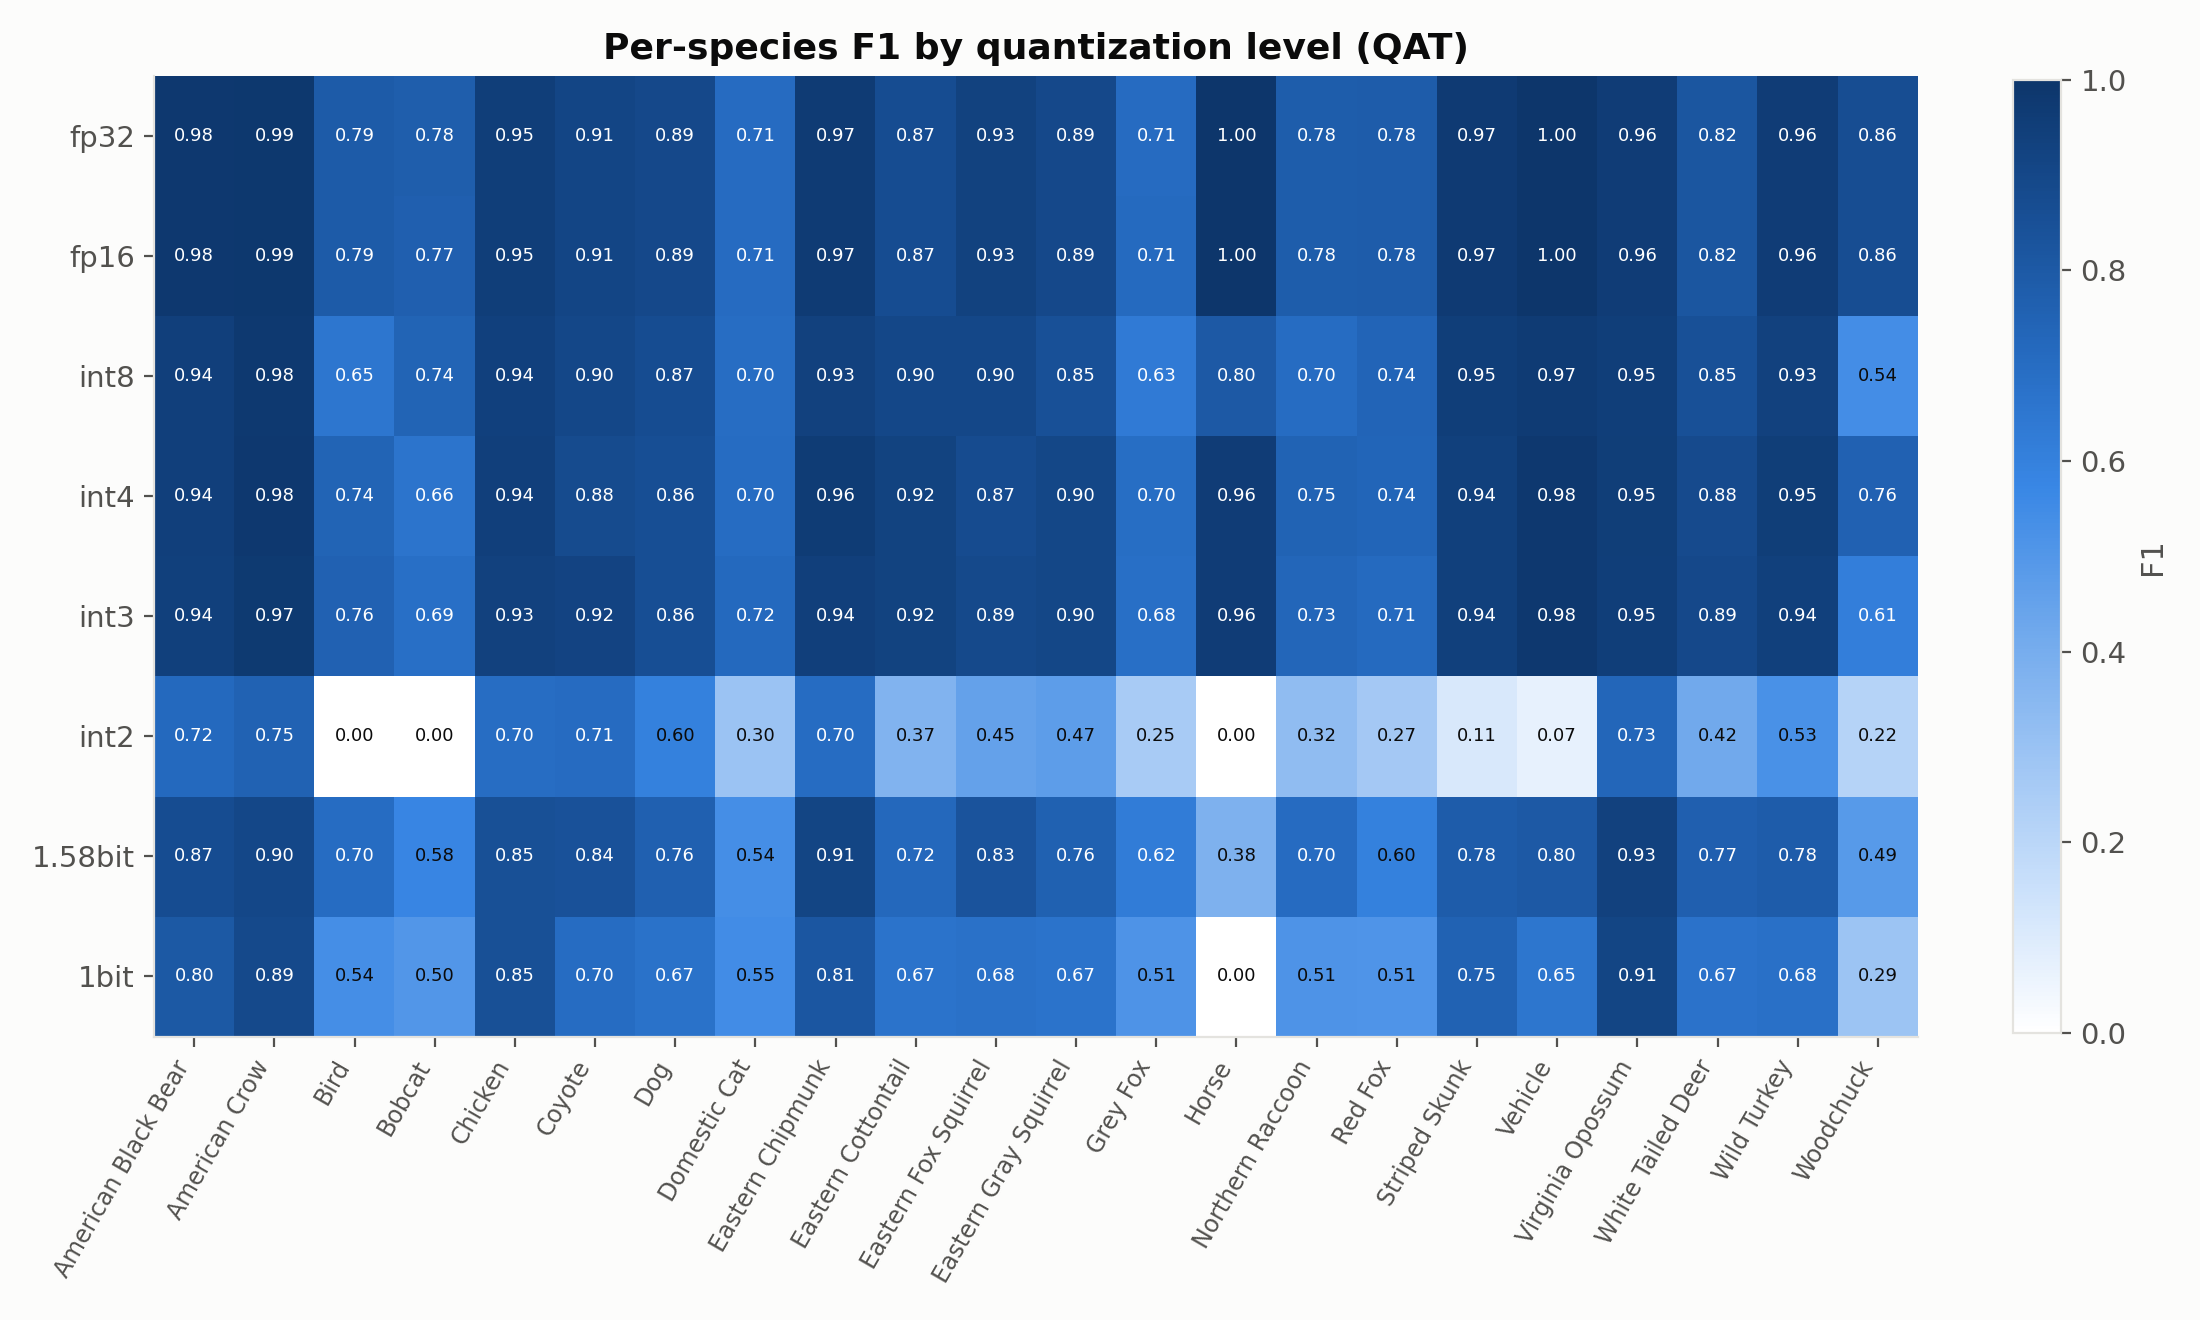

**09_confusion_matrices.png**

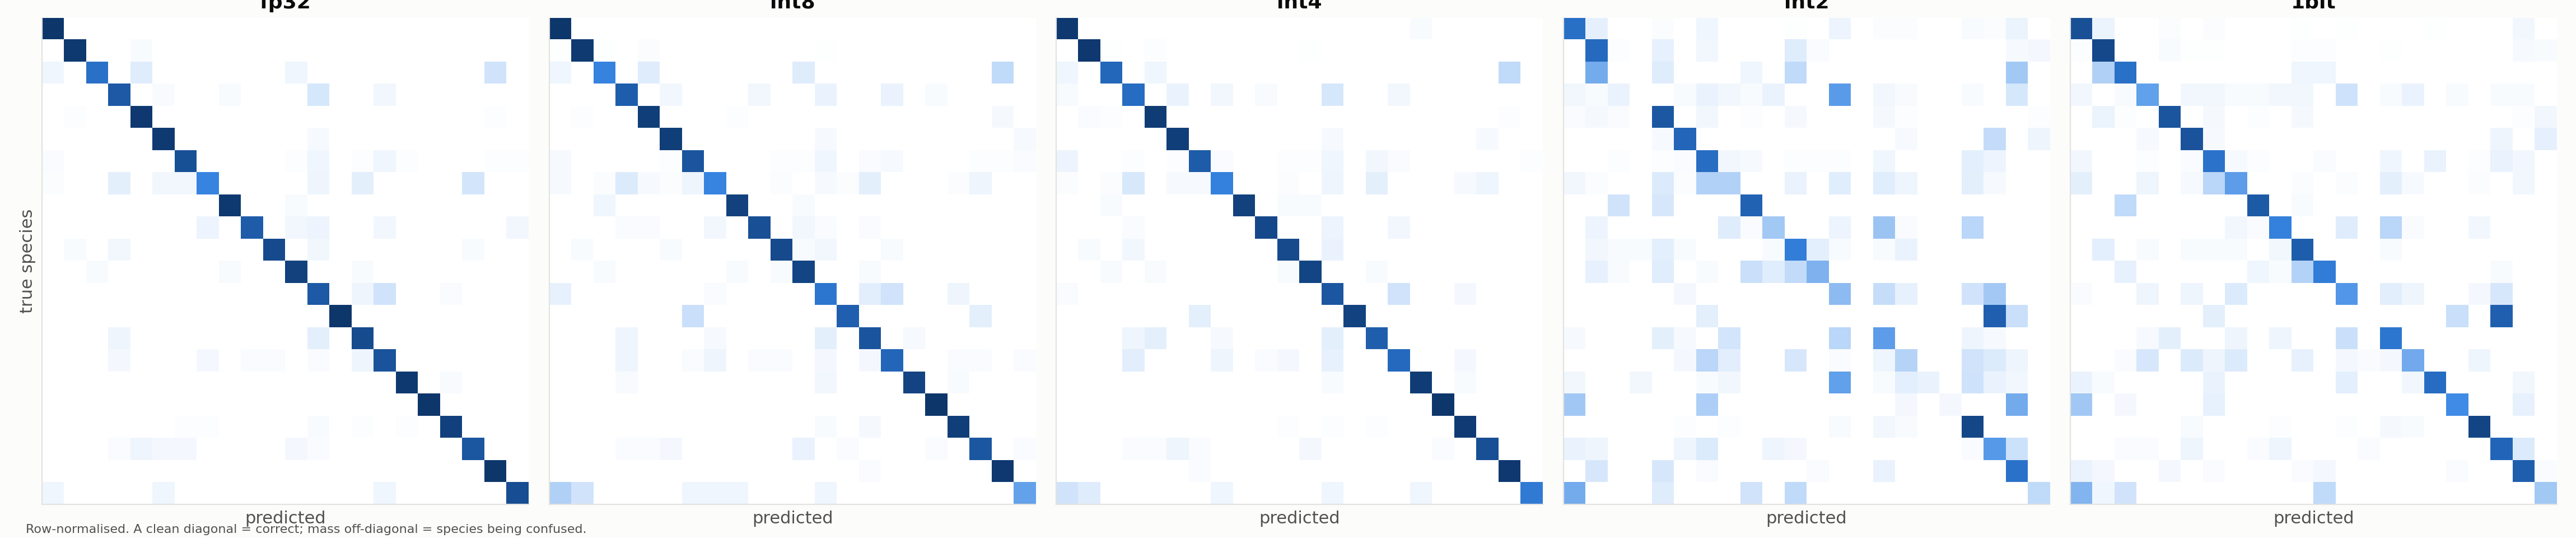

**10_memory_vs_batch.png**

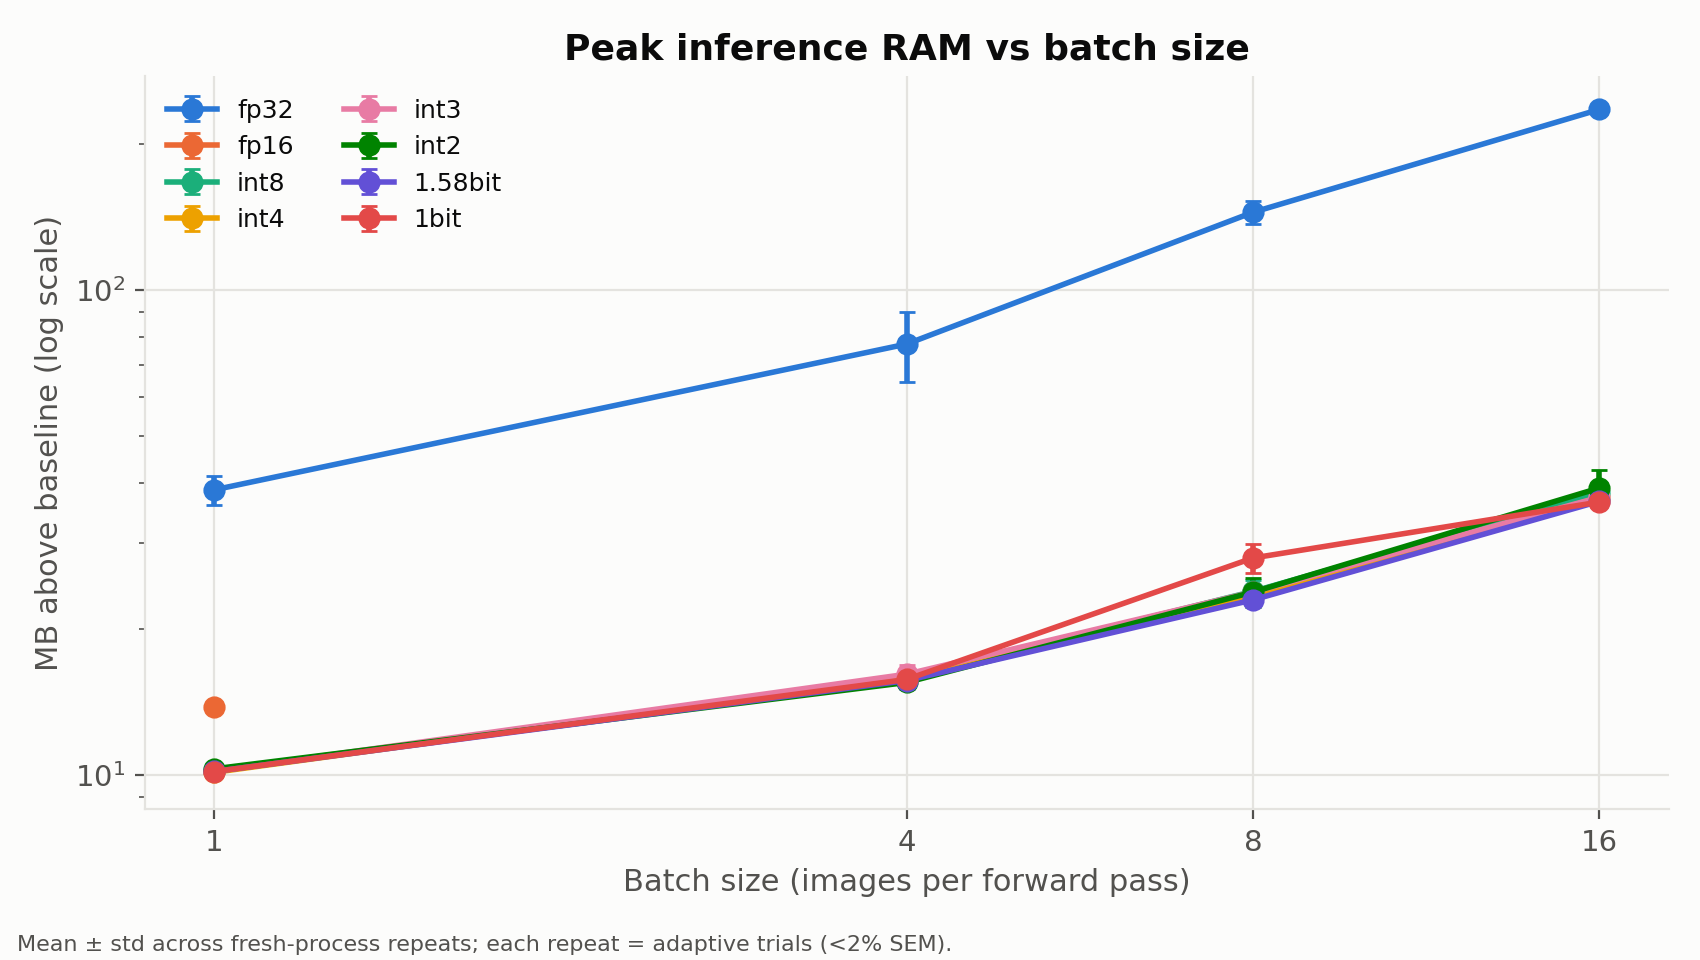

**11_resolution_effect.png**

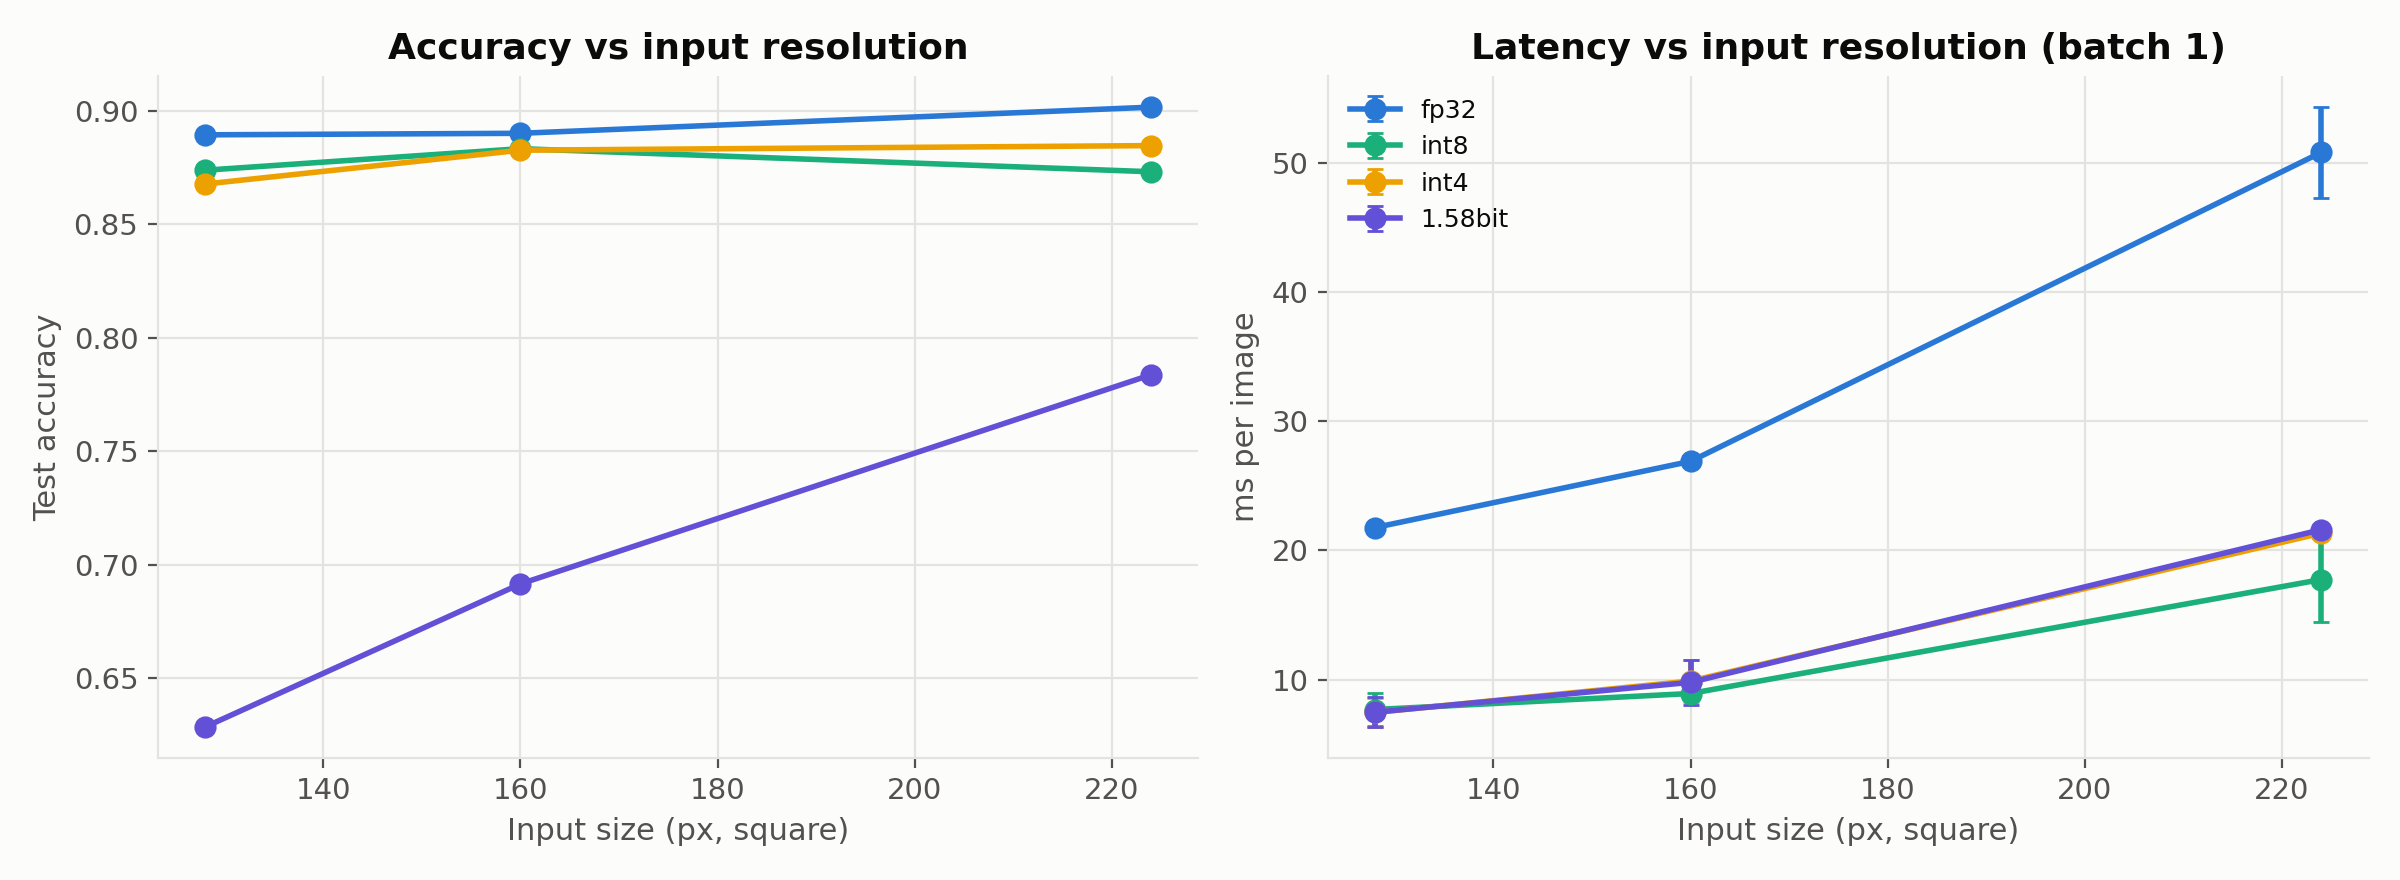

**12_device_comparison.png**

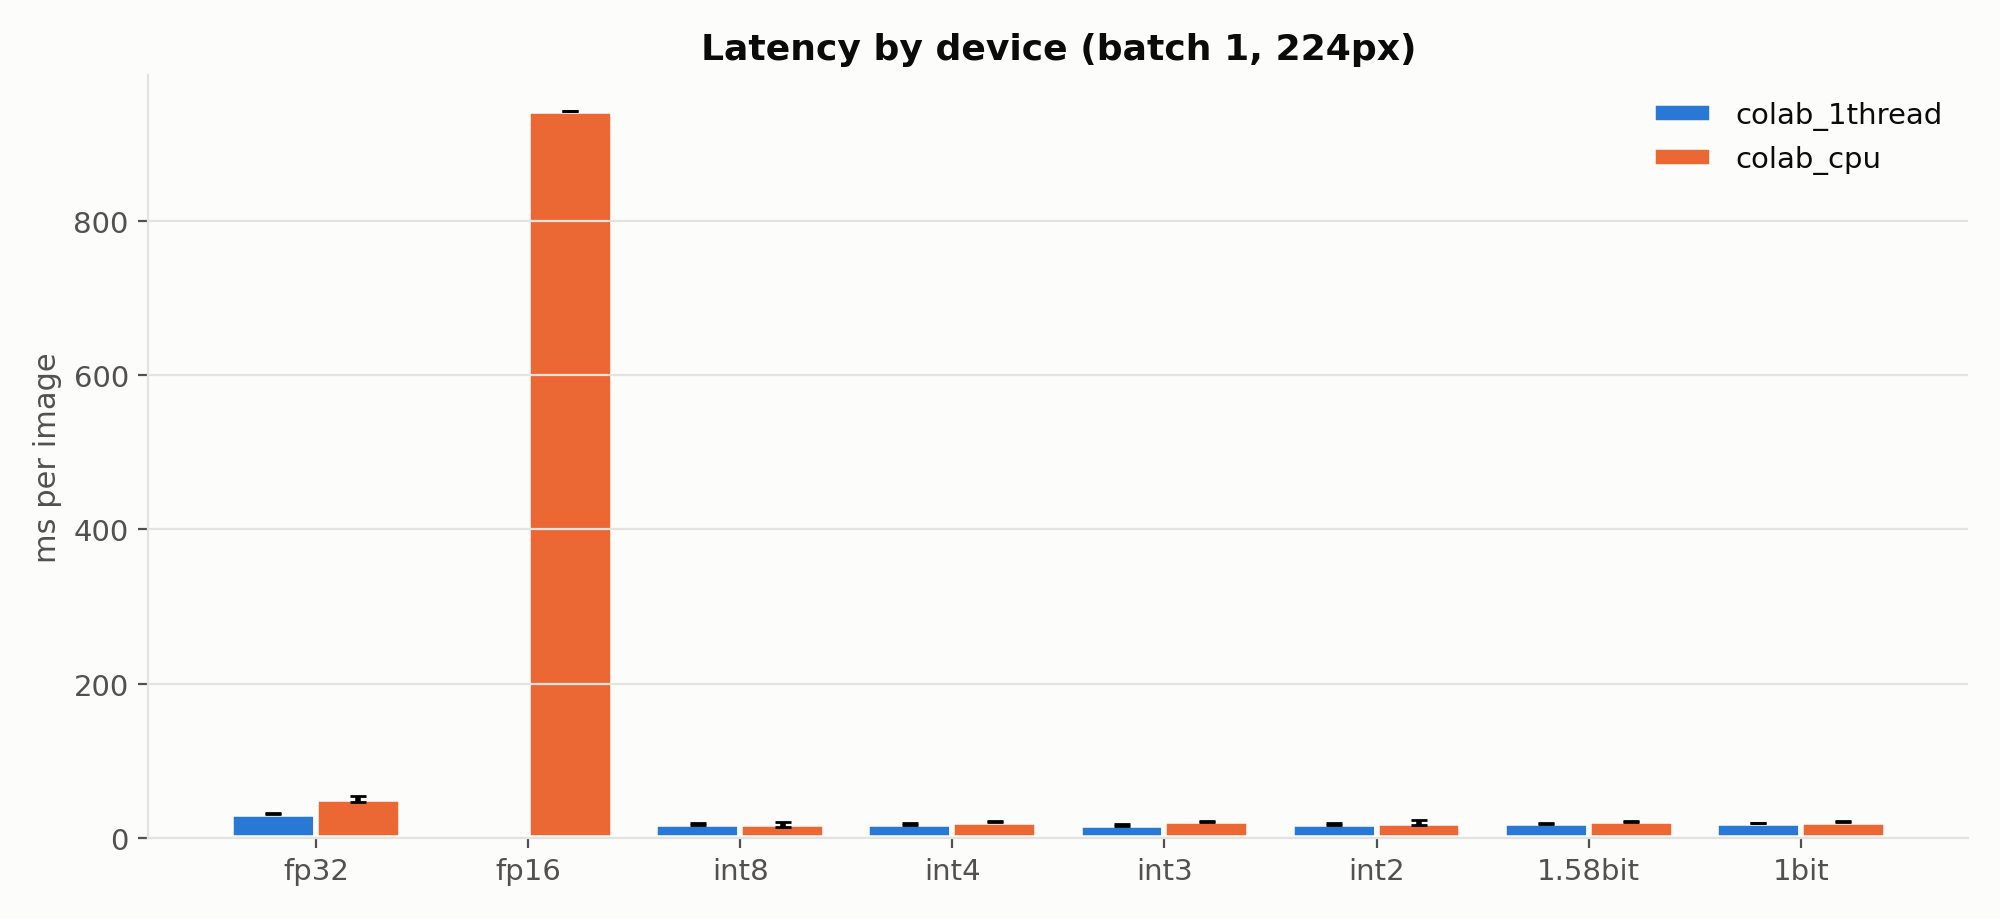

| model | accuracy | macro F1 | size (MB) | ms/img (bs 1) | img/s (bs 16) | peak RAM MB |
|---|---|---|---|---|---|---|
| fp32 | 0.902 ± 0.008 | 0.885 | 9.26 | 50.8 ± 3.5 | 22.9 ± 0.2 | 38.7 ± 2.7 |
| fp16 | 0.902 ± 0.008 | 0.885 | 4.67 (2.0× smaller) | 941.5 | — | 13.8 |
| int8-qat | 0.873 ± 0.009 | 0.833 | 2.37 (3.9× smaller) | 17.7 ± 3.3 | 76.6 ± 0.4 | 10.2 ± 0.1 |
| int8-ptq | 0.791 ± 0.010 | 0.752 | 2.37 (3.9× smaller) | 21.3 | — | 9.9 |
| int4-qat | 0.885 ± 0.008 | 0.862 | 1.31 (7.1× smaller) | 21.3 ± 0.2 | 76.7 ± 0.5 | 10.1 ± 0.1 |
| int4-ptq | 0.649 ± 0.012 | 0.598 | 1.31 (7.1× smaller) | 21.2 | — | 10.1 |
| int3-qat | 0.882 ± 0.008 | 0.856 | 1.04 (8.9× smaller) | 21.5 ± 0.2 | 68.9 ± 5.9 | 10.2 ± 0.2 |
| int3-ptq | 0.133 ± 0.009 | 0.054 | 1.04 (8.9× smaller) | 21.1 | — | 10.1 |
| int2-qat | 0.537 ± 0.014 | 0.395 | 0.78 (11.9× smaller) | 19.9 ± 3.5 | 68.6 ± 6.2 | 10.3 ± 0.2 |
| int2-ptq | 0.020 ± 0.004 | 0.002 | 0.78 (11.9× smaller) | 21.4 | — | 10.2 |
| 1.58bit-qat | 0.784 ± 0.011 | 0.732 | 0.67 (13.8× smaller) | 21.6 ± 0.2 | 75.9 ± 0.2 | 10.2 ± 0.1 |
| 1.58bit-ptq | 0.033 ± 0.005 | 0.004 | 0.67 (13.8× smaller) | 15.7 | — | 9.9 |
| 1bit-qat | 0.717 ± 0.012 | 0.628 | 0.51 (18.2× smaller) | 21.2 ± 0.6 | 73.8 ± 5.2 | 10.2 ± 0.2 |
| 1bit-ptq | 0.076 ± 0.007 | 0.006 | 0.51 (18.2× smaller) | 21.1 | — | 10.3 |


In [ ]:
# Show the figures right here
from IPython.display import Image, display, Markdown
for f in sorted(glob.glob('figures/*.png')):
    display(Markdown(f'**{Path(f).name}**')); display(Image(f, width=900))
display(Markdown(open('figures/summary_table.md').read()))

## Next
* Open **`notebooks/Live_Demo.ipynb`** to launch the app (public link for recording) and rehearse the live part.
* Everything is saved in Drive: `models/`, `results/`, `figures/`, `examples/`.